# RateBeer: Predicting the Overall Score a Reviewer Will Give a Beer

Web Mining and Recommender Systems · Assignment 2

Summary: Using 2.86 million RateBeer reviews (2000–2012), we predict the overall score (1–20) a user will give a beer from information available before the review. We train on the oldest 80% of reviews and test on the newest 10%. All models are from the course: bias models extended with beer information, time and a user × style offset, and a latent factor model. The best model reaches test MSE 5.40, 41% lower than predicting the average (9.09). The most useful information is which beer it is, its style and brewer, and how the user rates that style. New users remain the hardest case.

Contents
1. Predictive task and evaluation plan
2. Data, cleaning and exploratory analysis
3. Modeling
4. Evaluation
5. Related work
6. Conclusions

# 1. Predictive task and evaluation plan

Task: Predict the overall score (1–20) that a reviewer will give a beer, using only information available before the review is written. That includes who the reviewer is and how they rated other beers, which beer it is (its past ratings, style, brewer and ABV), and when the review happens (the date and how many reviews the reviewer has already written).

We do not use the appearance, aroma, palate and taste scores, because the reviewer enters them at the same moment as the overall score and they track it closely (correlations 0.56–0.88, Section 2.4.3). Using them would make the task trivial, and they don't exist for a beer the person hasn't tried yet. We do not use the review text, for a similar reason, because it is written after tasting the beer. We use it only in a separate comparison (Section 3.7) to show how much of the score is "written down" in the review.

How we evaluate
- Metric: MSE on the 1–20 scale, plus the fraction of variance unexplained (FVU = MSE ÷ variance of the scores) (Section 4.1).
- Split by time: oldest 80% of reviews for training, next 10% for validation, newest 10% for testing.
- Baselines: (1) always predict the training average; (2) predict the beer's average or the user's average; (3) the bias-only model with one offset per user and per beer.
- Models: the bias model extended with beer information (style, brewer, ABV), time (experience, year) and a user × style offset, and a latent factor model on top of it.
- Comparing feature representations: we add one group of information at a time (beer information, time, user × style) and measure the change in validation MSE. A second comparison looks at text representations (bag of words vs. TF-IDF).

How we check the results are valid
- Duplicate reviews are removed before splitting (Section 2.2.4), so no review appears in both training and test.
- Everything the models learn comes from training reviews only.
- Every model is scored on the same test set, and nothing is tuned on it.
- 95% bootstrap confidence intervals for the difference between models.
- Errors reported separately for new, rare and frequent users and beers, since heavy users dominate the overall MSE.

# 2. Data, cleaning and exploratory analysis

In [ ]:
import gzip, html, os, time, string
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

main_color, second_color, text_color = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.labelcolor": text_color,
    "xtick.color": text_color, "ytick.color": text_color,
})

## 2.1 Where the data comes from

- Source: the RateBeer file (`Ratebeer.txt.gz`, distributed through SNAP) from Professor Julian McAuley's dataset page at UCSD (https://cseweb.ucsd.edu/~jmcauley/datasets.html#multi_aspect), listed under "multi-aspect reviews" next to BeerAdvocate.
- What a review contains: beer name, beer ID, brewer ID, ABV, style, a date, the reviewer's profile name, the review text, and five scores: appearance (out of 5), aroma (10), palate (5), taste (10) and overall (20). Together the five add up to 50 points, which RateBeer divides by 10 to show a rating out of 5.
- Why it was collected: for research on reviews that rate several aspects of a product (McAuley, Leskovec & Jurafsky, "Learning attitudes and attributes from multi-aspect reviews", ICDM 2012) and on how reviewers' tastes change as they gain experience (McAuley & Leskovec, "From amateurs to connoisseurs", WWW 2013).
- Size according to the dataset page: 2,855,232 reviews, 40,213 users and 110,419 beers, April 2000 to November 2011. Our own counts are in Section 2.3.

In [ ]:
# Only needed on Google Colab
# Skip this cell when running locally
import os
if "google.colab" in str(get_ipython()):
    from google.colab import drive
    drive.mount("/content/drive")
    !cp "/content/drive/MyDrive/Ratebeer.txt.gz" /content/Ratebeer.txt.gz
print("Data file present:", os.path.exists("Ratebeer.txt.gz"))

Data file present: True


In [ ]:
DATA_PATH = "Ratebeer.txt.gz"
start_time = time.time()

field_names = {
    "beer/name": "beer_name", "beer/beerId": "beer_id", "beer/brewerId": "brewer_id",
    "beer/ABV": "abv", "beer/style": "beer_style", "review/appearance": "appearance",
    "review/aroma": "aroma", "review/palate": "palate", "review/taste": "taste",
    "review/overall": "overall", "review/time": "time", "review/profileName": "user",
    "review/text": "text",
}
column_values = {name: [] for name in field_names.values()}
shared_copy = {}
record, records_read, incomplete_records = {}, 0, 0

def save_record(record):
    global records_read, incomplete_records
    if len(record) != len(field_names):
        incomplete_records += 1
        return
    for column_name, value in record.items():
        if column_name != "text":
            value = shared_copy.setdefault(value, value)
        column_values[column_name].append(value)
    records_read += 1

# The file is plain text: one "key: value" line per field, and a blank line between reviews.
# It is Latin-1 encoded
with gzip.open(DATA_PATH, "rt", encoding="latin-1") as file:
    for line in file:
        line = line.rstrip("\n")
        if line == "":
            if record:
                save_record(record)
                record = {}
            continue
        key, _, value = line.partition(": ")
        if key in field_names:
            record[field_names[key]] = value.strip()
    if record:
        save_record(record)

df = pd.DataFrame(column_values)
del column_values, shared_copy

print(f"Reviews loaded: {len(df):,} | incomplete records skipped: {incomplete_records} "
      f"| time: {time.time() - start_time:.0f}s")
display(df.head(3))

Reviews loaded: 2,924,163 | incomplete records skipped: 0 | time: 32s


,beer_name,beer_id,brewer_id,abv,beer_style,appearance,aroma,palate,taste,overall,time,user,text
0,John Harvards Simcoe IPA,63836,8481,5.4,India Pale Ale &#40;IPA&#41;,4/5,6/10,3/5,6/10,13/20,1157587200,hopdog,"On tap at the Springfield, PA location. Poured..."
1,John Harvards Simcoe IPA,63836,8481,5.4,India Pale Ale &#40;IPA&#41;,4/5,6/10,4/5,7/10,13/20,1157241600,TomDecapolis,On tap at the John Harvards in Springfield PA....
2,John Harvards Cristal Pilsner,71716,8481,5,Bohemian Pilsener,4/5,5/10,3/5,6/10,14/20,958694400,PhillyBeer2112,"UPDATED: FEB 19, 2003 Springfield, PA. I've ne..."


Every review in the file was read in full. Every field, including the numbers, arrives as text (for example, ABV is `'5.4'` and overall is `'13/20'`), so it all needs converting.

## 2.2 Cleaning the data

### 2.2.1 Missing values that pandas can't see

`isnull()` only recognizes `None` and `NaN`. A placeholder such as `'-'` or an empty string `''` is ordinary text to pandas, so it is counted as a real value. That is why the first check reports nothing missing:

In [ ]:
pandas_missing_counts = df.isnull().sum()
print("Missing values reported by isnull():", pandas_missing_counts.sum())

Missing values reported by isnull(): 0


To find hidden placeholders, we scan every column for values that are empty, made only of symbols (no letter or digit, e.g. `'-'`), or common "missing" words such as `'n/a'` or `'null'`.

In [ ]:
null_words = ["n/a", "na", "null", "none", "nan", "unknown", "missing"]

placeholder_rows = []
for column_name in df.columns:
    values = df[column_name].str.strip()
    is_empty = values == ""
    is_symbols_only = ~values.str.contains(r"[A-Za-z0-9]") & ~is_empty
    short_values = values[values.str.len() <= 10]
    is_null_word = short_values.str.lower().isin(null_words)

    flagged = pd.concat([values[is_empty | is_symbols_only], short_values[is_null_word]])
    examples = []
    for flagged_value, count in flagged.value_counts().head(3).items():
        examples.append(repr(flagged_value[:12]) + " x " + str(count))

    placeholder_rows.append({"column": column_name, "empty": is_empty.sum(),
                             "symbols only": is_symbols_only.sum(), "missing-words": is_null_word.sum(),
                             "examples": ", ".join(examples)})
pd.DataFrame(placeholder_rows)

,column,empty,symbols only,missing-words,examples
0,beer_name,0,0,0,
1,beer_id,0,0,0,
2,brewer_id,0,0,0,
3,abv,0,138637,0,'-' x 138637
4,beer_style,0,0,0,
5,appearance,0,0,0,
6,aroma,0,0,0,
7,palate,0,0,0,
8,taste,0,0,0,
9,overall,0,0,0,


Three columns are flagged:
- abv: 138,637 reviews use `'-'` for an unknown ABV.
- text: 5,002 reviews are empty and 86 contain only symbols. A further check below finds texts with no letters at all and two import messages that say the review has no comments.
- user: 68 reviews come from a profile literally named `'missing'`. Its reviews cover 66 beers from 2006 to 2009 in one consistent writing style. We decided to keep it. An automatic scan only points at suspicious values.

In [ ]:
text_has_letters = df["text"].str.contains(r"[A-Za-z]")
system_messages = [
    "(This beer rating was imported from FB and unfortunately lacks any further comments.)",
    "Imported from Beerseek, no description given with original rating. Need to re-rate beer.",
]
is_system_message = df["text"].str.strip().isin(system_messages)
print("Texts with no letters:", (~text_has_letters).sum(), "| import messages with no review:", is_system_message.sum())
reviews_by_missing = df[df["user"] == "missing"]
missing_user_years = pd.to_datetime(pd.to_numeric(reviews_by_missing["time"]), unit="s").dt.year
print("Profile named 'missing':", len(reviews_by_missing), "reviews of", reviews_by_missing["beer_id"].nunique(),
      "different beers,", missing_user_years.min(), "to", missing_user_years.max())

df["abv"] = df["abv"].replace("-", np.nan)
df.loc[~text_has_letters | is_system_message, "text"] = np.nan

missing_after = df.isnull().sum()
missing_table = pd.DataFrame({"missing before": pandas_missing_counts, "missing after": missing_after,
                              "% of reviews": (missing_after / len(df) * 100).round(2)})
missing_table[missing_table["missing after"] > 0]

Texts with no letters: 5110 | import messages with no review: 75
Profile named 'missing': 68 reviews of 66 different beers, 2006 to 2009


,missing before,missing after,% of reviews
abv,0,138637,4.74
text,0,5185,0.18


Now, pandas sees 138,637 missing ABVs (4.74%) and 5,185 missing texts (0.18%). Before, it saw none.

### 2.2.2 Converting text to numbers and dates

In [ ]:
# Scores: "13/20" -> 13 (each column has at most 20 distinct values, so we check each one)
for column_name in ["appearance", "aroma", "palate", "taste", "overall"]:
    score_of = {}
    maximums_found = []
    for value in df[column_name].unique():
        parts = value.split("/")
        score_of[value] = int(parts[0])
        if int(parts[1]) not in maximums_found:
            maximums_found.append(int(parts[1]))
    df[column_name] = df[column_name].map(score_of)
    print(column_name.ljust(10), "maximum:", maximums_found, "| range:", df[column_name].min(), "to", df[column_name].max())

# ABV: raises an error if any non-number other than the removed "-" were left
df["abv"] = pd.to_numeric(df["abv"])

# Time: seconds since 1 Jan 1970 -> date
df["time"] = pd.to_numeric(df["time"])
df["date"] = pd.to_datetime(df["time"], unit="s")
print("Dates:", df["date"].min().date(), "to", df["date"].max().date(),
      "| timestamps that are not midnight:", (df["time"] % 86400 != 0).sum())
print("ABV range:", df["abv"].min(), "to", df["abv"].max(), "| reviews above 20% ABV:", (df["abv"] > 20).sum())

appearance maximum: [5] | range: 1 to 5
aroma      maximum: [10] | range: 1 to 10


palate     maximum: [5] | range: 1 to 5
taste      maximum: [10] | range: 1 to 10


overall    maximum: [20] | range: 1 to 20


Dates: 2000-04-12 to 2012-01-13 | timestamps that are not midnight: 0
ABV range: 0.01 to 57.7 | reviews above 20% ABV: 1631


- Every score has the form `score/maximum` with one maximum per column, and no score falls outside its range.
- Every timestamp is exactly midnight, so we know the date of a review but not the time of day.
- ABV runs from 0.01% (alcohol-free beers) to 57.7% (an extreme German eisbock). These are real beers, so nothing is removed.

### 2.2.3 HTML codes in names, styles and text

Names and styles contain web codes such as `&#40;` for "(" (the IPA style is stored as `India Pale Ale &#40;IPA&#41;`). We decode them with `html.unescape`. Accented letters are intact in this file (it is Latin-1 encoded, so "Kölsch" and "Märzen" read correctly), so no spelling repairs are needed.

In [ ]:
html_code_pattern = r"&#?[A-Za-z0-9]+;"
print("Reviews with HTML codes -> names:", df["beer_name"].str.contains(html_code_pattern).sum(),
      "| styles:", df["beer_style"].str.contains(html_code_pattern).sum(),
      "| texts:", df["text"].str.contains(html_code_pattern, na=False).sum())

for column_name in ["beer_name", "beer_style"]:
    cleaned_value_of = {value: html.unescape(value) for value in df[column_name].unique()}
    df[column_name] = df[column_name].map(cleaned_value_of)
text_has_code = df["text"].str.contains(html_code_pattern, na=False)
df.loc[text_has_code, "text"] = df.loc[text_has_code, "text"].apply(html.unescape)

print("Example style after cleaning:", df.loc[0, "beer_style"])
print("Style names with accented letters:", sorted(s for s in df["beer_style"].unique() if not s.isascii()))

Reviews with HTML codes -> names: 214417 | styles: 234046 | texts: 4547


Example style after cleaning: India Pale Ale (IPA)
Style names with accented letters: ['Bière de Garde', 'Kölsch', 'Oktoberfest/Märzen', 'Saké - Daiginjo', 'Saké - Futsu-shu', 'Saké - Genshu', 'Saké - Ginjo', 'Saké - Honjozo', 'Saké - Infused', 'Saké - Junmai', 'Saké - Koshu', 'Saké - Namasaké', 'Saké - Nigori', 'Saké - Taru', 'Saké - Tokubetsu']


### 2.2.4 Duplicate reviews

In [ ]:
print("Exact duplicate rows:", df.duplicated().sum())
repeated_pair = df.duplicated(subset=["user", "beer_id"], keep=False)
print("Extra copies of a (user, beer) pair:", df.duplicated(subset=["user", "beer_id"]).sum())

# What differs between the two copies?
repeated_rows = df[repeated_pair]
for column_name in ["brewer_id", "overall", "text", "date"]:
    pairs_that_differ = (repeated_rows.groupby(["user", "beer_id"])[column_name].nunique(dropna=False) > 1).sum()
    print("   pairs whose copies differ in", column_name.ljust(9), ":", pairs_that_differ)

df = df.drop_duplicates(subset=["user", "beer_id"], keep="first").reset_index(drop=True)
print("Reviews after removing copies:", len(df))

Exact duplicate rows: 4


Extra copies of a (user, beer) pair: 68931
   pairs whose copies differ in brewer_id : 68926
   pairs whose copies differ in overall   : 1


   pairs whose copies differ in text      : 2
   pairs whose copies differ in date      : 0


Reviews after removing copies: 2855232


Only 4 rows are exact copies, but 68,931 reviews appear twice, almost always identical except for the brewer ID. The beer is listed under two brewers (for example, a contract-brewed beer), and each review was collected once from each brewer's page. If one copy landed in the training set and the other in the test set, the model would be tested on a review it had already seen. Therefore, we keep the first copy.

After this step, we have 2,855,232 reviews, which is exactly the number on the dataset page. This confirms the duplicates were collection artifacts.

### 2.2.5 Cleaning summary

| Issue | What we did | Reviews affected |
|---|---|---|
| Empty record at the end of the file | Skipped while loading | 1 |
| ABV written as `'-'` | Set to NaN, rows kept, "ABV missing" handled in the models | 138,637 |
| Empty or meaningless review text | Set to NaN | 5,185 |
| Numbers stored as text | Checked format and range, converted to numbers and dates | all |
| HTML codes in names, styles and text | Decoded | ~450,000 |
| Same review collected twice | Kept the first copy | 68,931 removed |

## 2.3 Basic statistics

In [ ]:
reviews_per_user = df["user"].value_counts()
reviews_per_beer = df["beer_id"].value_counts()
df["word_count"] = df["text"].str.count(r"\S+")
density = len(df) / (df["user"].nunique() * df["beer_id"].nunique()) * 100
non_beer_styles = ["Cider", "Perry", "Ice Cider/Perry", "Mead"] + [style for style in df["beer_style"].unique() if style.startswith("Saké")]
print(f"Reviews of drinks that aren't beer (cider, perry, mead, saké): {df['beer_style'].isin(non_beer_styles).mean() * 100:.2f}%")

pd.DataFrame({"value": [
    f"{len(df):,}", f"{df['user'].nunique():,}", f"{df['beer_id'].nunique():,}", f"{df['brewer_id'].nunique():,}",
    f"{df['beer_style'].nunique()}", f"{df['date'].min().date()} to {df['date'].max().date()}",
    f"{df['word_count'].median():.0f}", f"{density:.3f}%",
]}, index=["reviews", "users (profile names)", "beers", "brewers", "styles", "dates",
           "median words per review", "density: reviews / (users x beers)"])

Reviews of drinks that aren't beer (cider, perry, mead, saké): 1.25%


,value
reviews,"2,855,232"
users (profile names),"29,265"
beers,"110,369"
brewers,"7,424"
styles,89
dates,2000-04-12 to 2012-01-13
median words per review,44
density: reviews / (users x beers),0.088%


- We have fewer users than the dataset page (29,265 vs. 40,213) because the file only has profile names and not user IDs.
- Only 0.088% of all possible (user, beer) pairs have a review, so the user–beer rating matrix is extremely sparse.
- About 1.25% of reviews are of drinks that aren't beer (cider, perry, mead, saké). They use the same scale, so we keep them.

The target we're choosing is the overall score.

mean 13.24 | median 14 | standard deviation 3.33 | variance 11.07 | skew -1.03
share of scores from 12 to 17: 71.0%


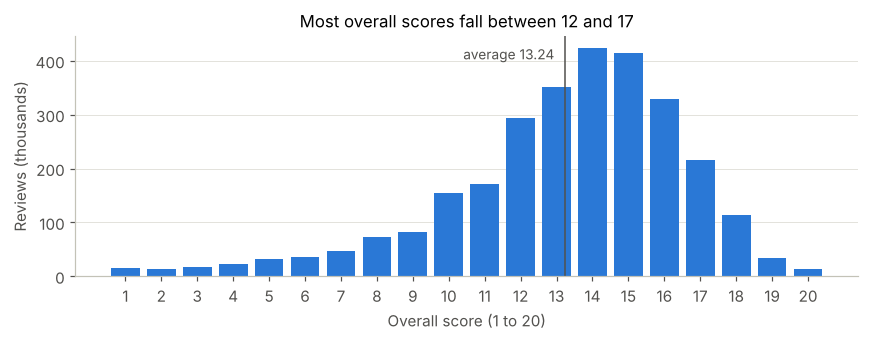

In [ ]:
overall_counts = df["overall"].value_counts().sort_index()
overall_mean = df["overall"].mean()
overall_variance = ((df["overall"] - overall_mean) ** 2).mean()
print(f"mean {overall_mean:.2f} | median {df['overall'].median():.0f} | standard deviation {overall_variance ** 0.5:.2f}"
      f" | variance {overall_variance:.2f} | skew {df['overall'].skew():.2f}")
print(f"share of scores from 12 to 17: {df['overall'].between(12, 17).mean() * 100:.1f}%")

figure, axis = plt.subplots(figsize=(8, 3.2))
axis.bar(overall_counts.index, overall_counts.values / 1000, color=main_color, width=0.8)
axis.axvline(overall_mean, color=text_color, linewidth=1)
axis.text(overall_mean - 0.3, overall_counts.max() / 1000 * 0.95, f"average {overall_mean:.2f}", ha="right", color=text_color, fontsize=9)
axis.set_xticks(range(1, 21))
axis.set_xlabel("Overall score (1 to 20)")
axis.set_ylabel("Reviews (thousands)")
axis.set_title("Most overall scores fall between 12 and 17")
axis.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

The average overall score is 13.24, and 71% of scores fall between 12 and 17. The distribution leans left (skew −1.03): low scores trail off in a long tail while top scores are rare. Always predicting the average gives an MSE equal to the variance (11.07), which is the bar every model must clear.

## 2.4 Patterns in the data

### 2.4.1 A few users and beers account for most reviews

users: % of users per bucket {'1': 32.8, '2-5': 27.5, '6-10': 9.5, '11-50': 14.0, '51-100': 3.9, '101-500': 7.7, '501-1000': 2.1, 'over 1000': 2.5}
users: % of all reviews per bucket {'1': 0.3, '2-5': 0.8, '6-10': 0.8, '11-50': 3.2, '51-100': 2.9, '101-500': 18.0, '501-1000': 15.0, 'over 1000': 59.0}
beers: % of beers per bucket {'1': 22.5, '2-5': 34.0, '6-10': 14.5, '11-50': 20.9, '51-100': 3.7, '101-500': 3.7, '501-1000': 0.6, 'over 1000': 0.3}
beers: % of all reviews per bucket {'1': 0.9, '2-5': 4.1, '6-10': 4.3, '11-50': 17.9, '51-100': 10.1, '101-500': 30.3, '501-1000': 15.8, 'over 1000': 16.7}


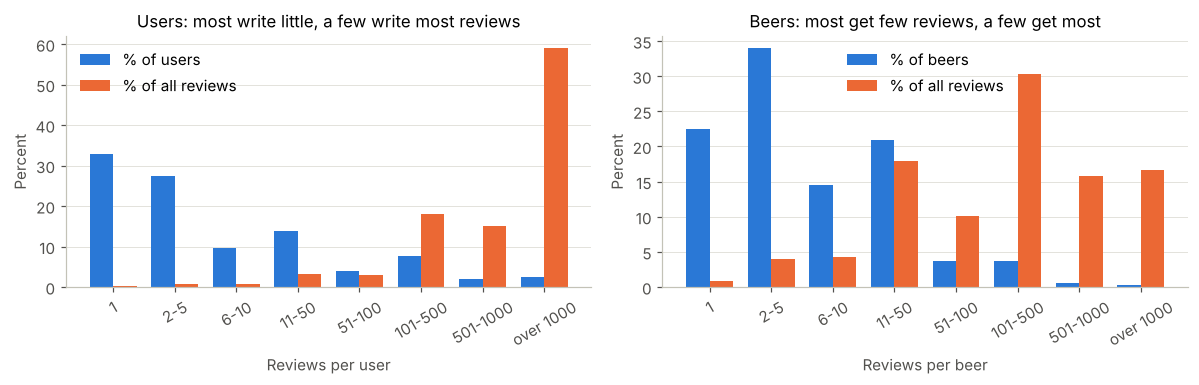

In [ ]:
bucket_edges = [0, 1, 5, 10, 50, 100, 500, 1000, 100000]
bucket_labels = ["1", "2-5", "6-10", "11-50", "51-100", "101-500", "501-1000", "over 1000"]

figure, axes = plt.subplots(1, 2, figsize=(11, 3.6))
bar_positions = np.arange(len(bucket_labels))
for axis, counts, group_label in [(axes[0], reviews_per_user, "users"), (axes[1], reviews_per_beer, "beers")]:
    bucket = pd.cut(counts, bins=bucket_edges, labels=bucket_labels)
    share_of_group = bucket.value_counts(normalize=True).sort_index() * 100
    share_of_reviews = counts.groupby(bucket, observed=False).sum() / len(df) * 100
    print(f"{group_label}: % of {group_label} per bucket", share_of_group.round(1).to_dict())
    print(f"{group_label}: % of all reviews per bucket", share_of_reviews.round(1).to_dict())
    axis.bar(bar_positions - 0.19, share_of_group.values, width=0.38, color=main_color, label="% of " + group_label)
    axis.bar(bar_positions + 0.19, share_of_reviews.values, width=0.38, color=second_color, label="% of all reviews")
    axis.set_xticks(bar_positions)
    axis.set_xticklabels(bucket_labels, rotation=30)
    axis.set_xlabel("Reviews per " + group_label[:-1])
    axis.set_ylabel("Percent")
    axis.grid(axis="x", visible=False)
    axis.legend(frameon=False)
axes[0].set_title("Users: most write little, a few write most reviews")
axes[1].set_title("Beers: most get few reviews, a few get most")
plt.tight_layout()
plt.show()

A third of users wrote one review, yet the 4.6% who wrote more than 500 reviews produced 74% of all reviews. Likewise, 4.6% of beers (those with over 100 reviews) received 63% of the reviews. An MSE over all reviews is therefore driven mostly by heavy users and popular beers, so we also report errors for rarely seen users and beers (the cold-start case, Section 4.4).

### 2.4.2 Scores change over time

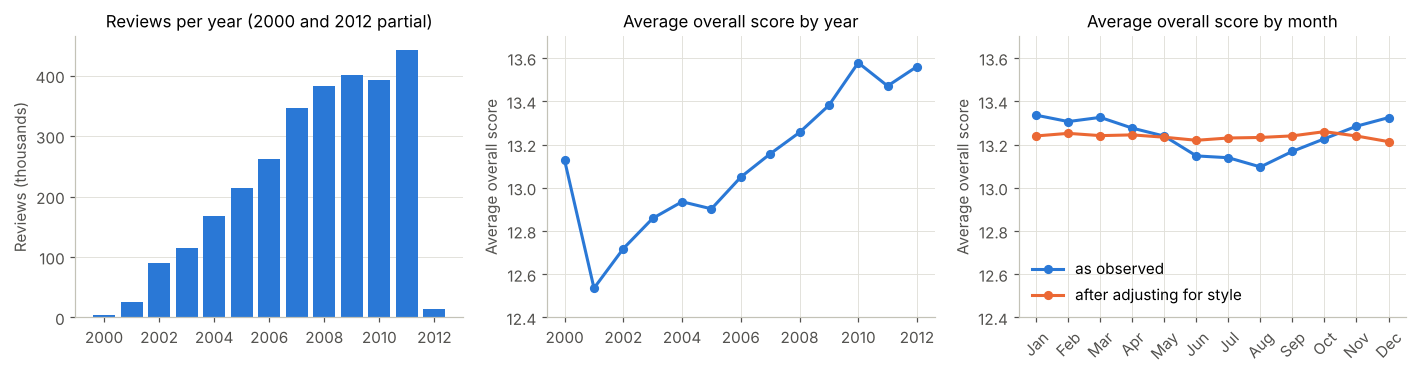

Average by month: {1: 13.34, 2: 13.31, 3: 13.33, 4: 13.28, 5: 13.24, 6: 13.15, 7: 13.14, 8: 13.1, 9: 13.17, 10: 13.23, 11: 13.28, 12: 13.32}
Monthly swing as observed: 0.24 | after adjusting for style: 0.05
Imperial Stout: 5.0% of January reviews vs 3.5% of August reviews


Pale Lager: 4.8% of January reviews vs 5.1% of August reviews


In [ ]:
review_year = df["date"].dt.year
review_month = df["date"].dt.month
reviews_per_year = df.groupby(review_year)["overall"].count()
average_by_year = df.groupby(review_year)["overall"].mean()
average_by_month = df.groupby(review_month)["overall"].mean()

# Remove the effect of which styles people review in each month: score minus the style's average
style_average = df.groupby("beer_style")["overall"].transform("mean")
style_adjusted_by_month = (df["overall"] - style_average).groupby(review_month).mean() + overall_mean

figure, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].bar(reviews_per_year.index, reviews_per_year.values / 1000, color=main_color)
axes[0].set_title("Reviews per year (2000 and 2012 partial)")
axes[0].set_ylabel("Reviews (thousands)")
axes[0].grid(axis="x", visible=False)
axes[1].plot(average_by_year.index, average_by_year.values, color=main_color, linewidth=2, marker="o", markersize=5)
axes[1].set_title("Average overall score by year")
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
axes[2].plot(range(1, 13), average_by_month.values, color=main_color, linewidth=2, marker="o", markersize=5, label="as observed")
axes[2].plot(range(1, 13), style_adjusted_by_month.values, color=second_color, linewidth=2, marker="o", markersize=5, label="after adjusting for style")
axes[2].set_xticks(range(1, 13))
axes[2].set_xticklabels(month_names, rotation=45)
axes[2].set_title("Average overall score by month")
axes[2].legend(frameon=False, loc="lower left")
for axis in axes[:2]:
    axis.set_xticks(range(2000, 2013, 2))
for axis in axes[1:]:
    axis.set_ylim(12.4, 13.7)
    axis.set_ylabel("Average overall score")
plt.tight_layout()
plt.show()

print("Average by month:", average_by_month.round(2).to_dict())
print(f"Monthly swing as observed: {average_by_month.max() - average_by_month.min():.2f} | "
      f"after adjusting for style: {style_adjusted_by_month.max() - style_adjusted_by_month.min():.2f}")
for style_name in ["Imperial Stout", "Pale Lager"]:
    share_by_month = (df["beer_style"] == style_name).groupby(review_month).mean() * 100
    print(f"{style_name}: {share_by_month[1]:.1f}% of January reviews vs {share_by_month[8]:.1f}% of August reviews")

- Year: activity grows to about 400,000 reviews a year by 2009–2011, and the average score climbs from about 12.5 (2001) to about 13.5 (2010–2012). A year feature or a time-dependent bias can capture this.
- Month: scores are lowest in August (13.10) and highest in January (13.34). The orange line shows that this is mostly a style effect. People review more imperial stouts in winter and fewer in summer, and stouts score high. After subtracting each style's average, the monthly swing shrinks from 0.24 to about 0.05 points. So style matters much more than the calendar month.
- Both line charts share one y-axis, so the yearly drift (about 1 point) can be compared directly with the monthly swing.

### 2.4.3 How the overall score relates to the other columns

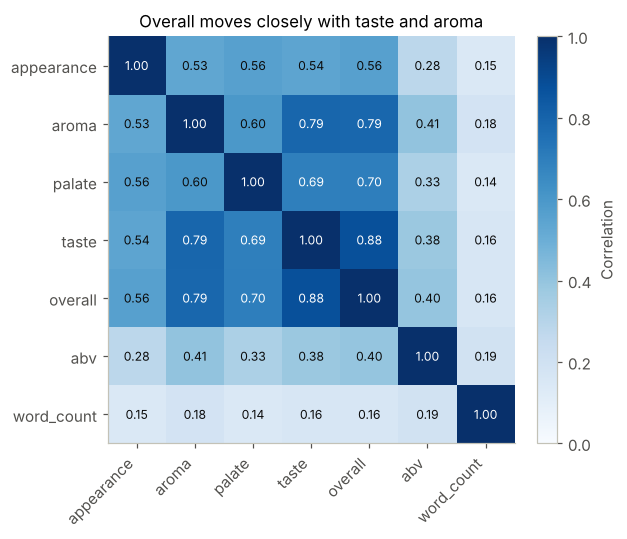

In [ ]:
correlation_columns = ["appearance", "aroma", "palate", "taste", "overall", "abv", "word_count"]
correlation_matrix = df[correlation_columns].corr()

figure, axis = plt.subplots(figsize=(6.2, 5))
image = axis.imshow(correlation_matrix.values, cmap="Blues", vmin=0, vmax=1)
axis.set_xticks(range(len(correlation_columns)))
axis.set_yticks(range(len(correlation_columns)))
axis.set_xticklabels(correlation_columns, rotation=45, ha="right")
axis.set_yticklabels(correlation_columns)
axis.grid(False)
for row_number in range(len(correlation_columns)):
    for column_number in range(len(correlation_columns)):
        value = correlation_matrix.values[row_number, column_number]
        axis.text(column_number, row_number, f"{value:.2f}", ha="center", va="center", fontsize=8,
                  color="white" if value > 0.6 else "#0b0b0b")
figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04, label="Correlation")
axis.set_title("Overall moves closely with taste and aroma")
plt.tight_layout()
plt.show()

The four other scores are almost the same opinion as the overall score (taste 0.88, aroma 0.79, palate 0.70, appearance 0.56). They are entered at the same moment, so a model that uses them would mostly learn how people combine their own sub-scores, and it couldn't predict a score for a beer the user hasn't reviewed yet. ABV (0.40) and review length (0.16) are weaker but real signals.

### 2.4.4 Beer style and strength

Most reviewed styles: India Pale Ale (IPA), Pale Lager, Belgian Strong Ale, Imperial Stout, Imperial/Double IPA
Lowest: {'Low Alcohol': 6.33, 'Malt Liquor': 6.81, 'Pale Lager': 7.49}
Highest: {'Abt/Quadrupel': 15.68, 'Ice Cider/Perry': 15.81, 'Imperial Stout': 15.87}


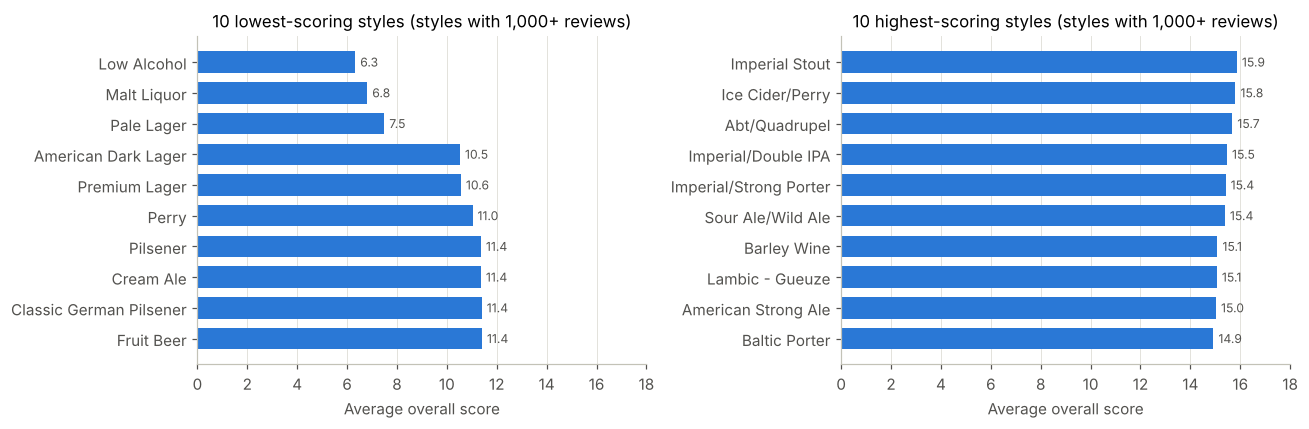

In [ ]:
style_summary = df.groupby("beer_style")["overall"].agg(["mean", "count"])
common_styles = style_summary[style_summary["count"] >= 1000].sort_values("mean")
print("Most reviewed styles:", ", ".join(style_summary.sort_values("count", ascending=False).index[:5]))
print("Lowest:", common_styles["mean"].head(3).round(2).to_dict())
print("Highest:", common_styles["mean"].tail(3).round(2).to_dict())

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, styles_to_plot, panel_title in [(axes[0], common_styles.head(10).iloc[::-1], "10 lowest-scoring styles"),
                                          (axes[1], common_styles.tail(10), "10 highest-scoring styles")]:
    axis.barh(styles_to_plot.index, styles_to_plot["mean"], color=main_color, height=0.7)
    for row_number, average_score in enumerate(styles_to_plot["mean"]):
        axis.text(average_score + 0.2, row_number, f"{average_score:.1f}", va="center", fontsize=8, color=text_color)
    axis.set_xlim(0, 18)
    axis.set_xlabel("Average overall score")
    axis.set_title(panel_title + " (styles with 1,000+ reviews)")
    axis.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Average overall by ABV range: {'0-3': 7.33, '3-4': 11.28, '4-5': 11.48, '5-6': 12.94, '6-7': 14.09, '7-8': 14.38, '8-9': 14.7, '9-10': 15.24, '10-12': 15.47, '12-15': 15.48, '15+': 15.08}


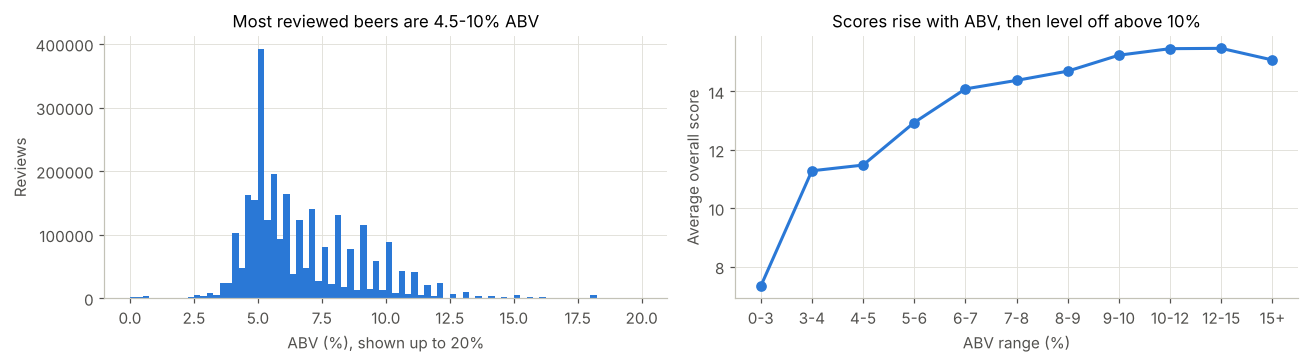

In [ ]:
abv_edges = [0, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 60]
abv_labels = ["0-3", "3-4", "4-5", "5-6", "6-7", "7-8", "8-9", "9-10", "10-12", "12-15", "15+"]
average_by_abv = df.groupby(pd.cut(df["abv"], bins=abv_edges, labels=abv_labels), observed=False)["overall"].mean()
print("Average overall by ABV range:", average_by_abv.round(2).to_dict())

figure, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].hist(df["abv"].dropna(), bins=np.arange(0, 20.25, 0.25), color=main_color)
axes[0].set_xlabel("ABV (%), shown up to 20%")
axes[0].set_ylabel("Reviews")
axes[0].set_title("Most reviewed beers are 4.5-10% ABV")
axes[1].plot(abv_labels, average_by_abv.values, color=main_color, linewidth=2, marker="o", markersize=6)
axes[1].set_xlabel("ABV range (%)")
axes[1].set_ylabel("Average overall score")
axes[1].set_title("Scores rise with ABV, then level off above 10%")
plt.tight_layout()
plt.show()

- Style: averages run from about 6 (low-alcohol beer, malt liquor) to almost 16 (imperial stout, quadrupel, double IPA). Style is a strong candidate feature (one-hot encoded). IPA is the most reviewed style.
- ABV: most reviews are of 4.5–10% beers. The average score climbs from 7.3 below 3% to about 15.5 at 10–15%, then dips slightly. A curve like this needs more than one straight-line term, for example ABV plus ABV², as in the course's beer regression example. Style and ABV overlap, because strong styles are high in alcohol.

### 2.4.5 Review text

Average overall by review length: {'1-20': 11.99, '21-40': 12.79, '41-60': 13.44, '61-80': 13.76, '81-100': 14.0, '101-150': 14.21, '151-200': 14.5, '200+': 14.84}


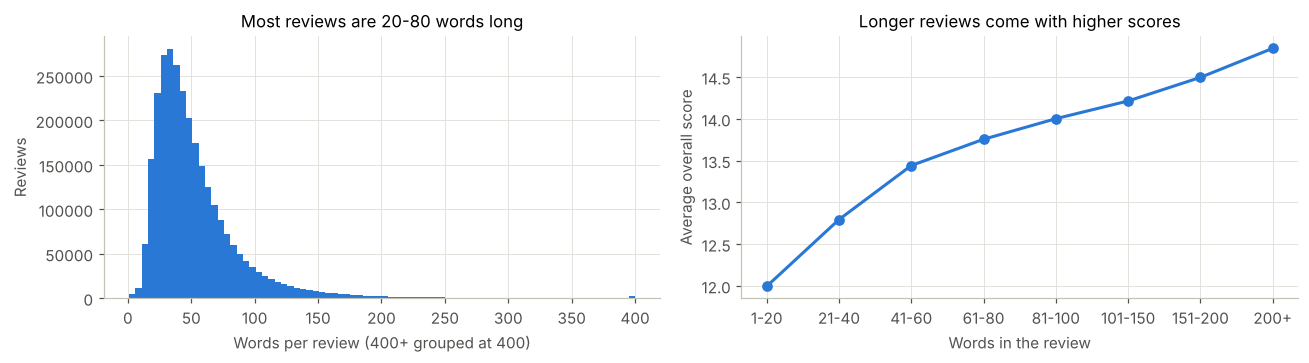

In [ ]:
length_edges = [0, 20, 40, 60, 80, 100, 150, 200, 5000]
length_labels = ["1-20", "21-40", "41-60", "61-80", "81-100", "101-150", "151-200", "200+"]
average_by_length = df.groupby(pd.cut(df["word_count"], bins=length_edges, labels=length_labels), observed=False)["overall"].mean()
print("Average overall by review length:", average_by_length.round(2).to_dict())

figure, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].hist(df["word_count"].dropna().clip(upper=400), bins=80, color=main_color)
axes[0].set_xlabel("Words per review (400+ grouped at 400)")
axes[0].set_ylabel("Reviews")
axes[0].set_title("Most reviews are 20-80 words long")
axes[1].plot(length_labels, average_by_length.values, color=main_color, linewidth=2, marker="o", markersize=6)
axes[1].set_xlabel("Words in the review")
axes[1].set_ylabel("Average overall score")
axes[1].set_title("Longer reviews come with higher scores")
plt.tight_layout()
plt.show()

Another question we wanted to answer was: Which words separate low scores (8 or less) from high scores (17 or more)?

We used a sample of 50,000 reviews to investigate this.

In [ ]:
sampled_reviews = df.loc[df["text"].notnull(), ["text", "overall"]].sample(n=50000, random_state=42)
punctuation = set(string.punctuation)
low_word_counts, high_word_counts = defaultdict(int), defaultdict(int)
total_low_words, total_high_words = 0, 0

for review_text, overall_score in zip(sampled_reviews["text"], sampled_reviews["overall"]):
    if 8 < overall_score < 17:
        continue
    words = "".join([character for character in review_text.lower() if character not in punctuation]).split()
    for word in words:
        if overall_score <= 8:
            low_word_counts[word] += 1
        else:
            high_word_counts[word] += 1
    if overall_score <= 8:
        total_low_words += len(words)
    else:
        total_high_words += len(words)

word_rows = []
for word in set(low_word_counts) | set(high_word_counts):
    if low_word_counts[word] + high_word_counts[word] < 50:
        continue
    low_rate = low_word_counts[word] / total_low_words * 10000      # uses per 10,000 words
    high_rate = high_word_counts[word] / total_high_words * 10000
    word_rows.append({"word": word, "low": (low_rate + 1) / (high_rate + 1), "high": (high_rate + 1) / (low_rate + 1)})
word_table = pd.DataFrame(word_rows)
low_words = word_table.sort_values("low", ascending=False).head(12)
high_words = word_table.sort_values("high", ascending=False).head(12)
pd.DataFrame({"low-score word": low_words["word"].values, "x more common in low reviews": low_words["low"].round(1).values,
              "high-score word": high_words["word"].values, "x more common in high reviews": high_words["high"].round(1).values},
             index=range(1, 13))

,low-score word,x more common in low reviews,high-score word,x more common in high reviews
1,corn,18.6,bourbon,12.6
2,watery,15.8,rich,10.2
3,boring,8.6,complex,8.6
4,bland,8.5,excellent,8.2
5,water,7.8,oak,7.7
6,weak,7.6,delicious,7.3
7,cheap,7.6,chocolate,7.3
8,bad,7.4,coffee,6.7
9,skunky,7.2,balanced,6.3
10,lager,6.9,pine,6.2


Review length and score rise together (about 12.0 for very short reviews, 14.8 for reviews over 200 words). Low scores bring words like corn, watery, bland, skunky, cheap; high scores bring bourbon, rich, complex, oak, delicious. The text clearly carries information about the score, so a bag-of-words model is a sensible comparison setting.

### 2.4.6 Some users are more generous, and some beers are better liked

users with 10+ reviews: 9,233, spread of their averages (st. dev.) 1.98
   middle half of users average between 12.4 and 14.8
beers with 10+ reviews: 34,477, spread of their averages (st. dev.) 2.30


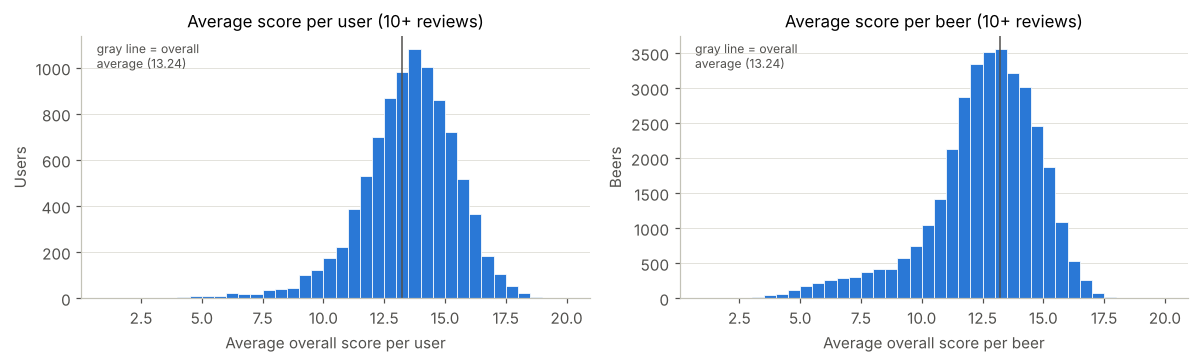

In [ ]:
user_summary = df.groupby("user")["overall"].agg(["mean", "count"])
beer_summary = df.groupby("beer_id")["overall"].agg(["mean", "count"])
active_users = user_summary[user_summary["count"] >= 10]["mean"]
reviewed_beers = beer_summary[beer_summary["count"] >= 10]["mean"]
print(f"users with 10+ reviews: {len(active_users):,}, spread of their averages (st. dev.) {active_users.std():.2f}")
print(f"   middle half of users average between {active_users.quantile(0.25):.1f} and {active_users.quantile(0.75):.1f}")
print(f"beers with 10+ reviews: {len(reviewed_beers):,}, spread of their averages (st. dev.) {reviewed_beers.std():.2f}")

figure, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for axis, averages, label in [(axes[0], active_users, "user"), (axes[1], reviewed_beers, "beer")]:
    axis.hist(averages, bins=np.arange(1, 20.5, 0.5), color=main_color, edgecolor="white", linewidth=0.5)
    axis.axvline(overall_mean, color=text_color, linewidth=1)
    axis.text(0.03, 0.88, f"gray line = overall\naverage ({overall_mean:.2f})", transform=axis.transAxes, color=text_color, fontsize=8)
    axis.set_xlabel(f"Average overall score per {label}")
    axis.set_ylabel(label.capitalize() + "s")
    axis.set_title(f"Average score per {label} (10+ reviews)")
    axis.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Users differ in how generous they are: the middle half of users have average scores between 12.4 and 14.8. Beers differ even more than users (the standard deviation of beer averages is 2.30, vs. 1.98 for users). This is what a bias-only model captures: one offset for each user and one for each beer.

### 2.4.7 Experience and reviewing many beers in one day

By review number: {'1': 14.45, '2-5': 13.76, '6-10': 13.42, '11-25': 13.33, '26-50': 13.22, '51-100': 13.24, '101-250': 13.34, '251-500': 13.33, '501-1000': 13.3, '1001-2500': 13.17, '2500+': 12.79}
Compared with own average (users with 50+ reviews): {'1': 0.59, '2-5': 0.19, '6-10': 0.01, '11-25': -0.14, '26-50': -0.2, '51-100': -0.15, '101-250': -0.05, '251-500': -0.02, '501-1000': 0.01, '1001-2500': 0.05, '2500+': 0.15}
By reviews on the same day: {'1': 13.72, '2': 13.47, '3': 13.33, '4-5': 13.26, '6-10': 13.11, '11-20': 12.96, '21-50': 12.77, '50+': 12.6}


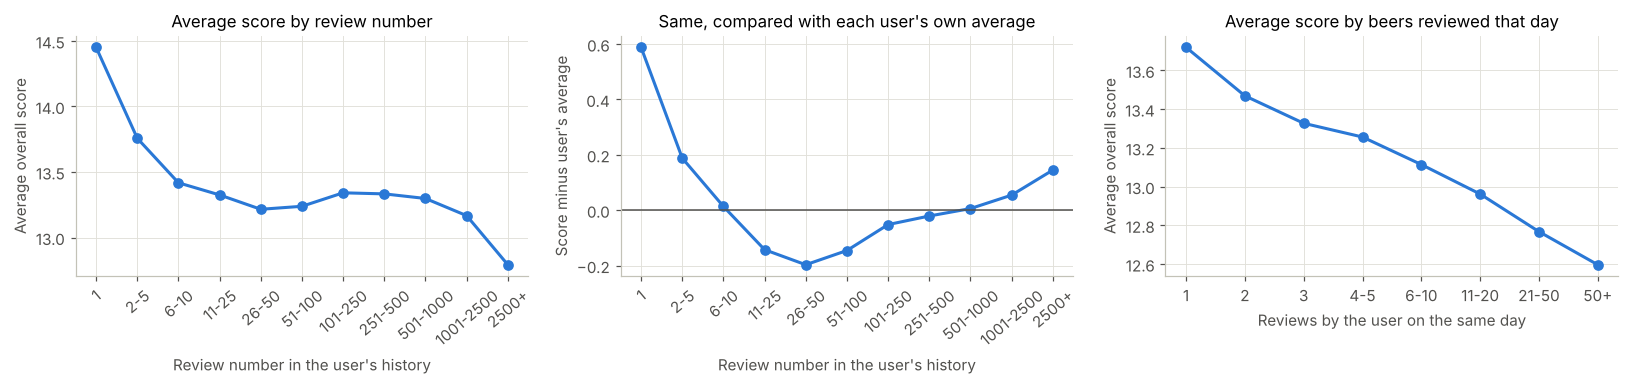

In [ ]:
user_history = df[["user", "date", "overall"]].sort_values(["user", "date"], kind="stable")
df["review_number"] = user_history.groupby("user").cumcount() + 1
df["reviews_same_day"] = user_history.groupby(["user", "date"])["overall"].transform("size")       # reviews that user wrote that day

experience_edges = [0, 1, 5, 10, 25, 50, 100, 250, 500, 1000, 2500, 100000]
experience_labels = ["1", "2-5", "6-10", "11-25", "26-50", "51-100", "101-250", "251-500", "501-1000", "1001-2500", "2500+"]
experience_range = pd.cut(df["review_number"], bins=experience_edges, labels=experience_labels)
same_day_edges = [0, 1, 2, 3, 5, 10, 20, 50, 100000]
same_day_labels = ["1", "2", "3", "4-5", "6-10", "11-20", "21-50", "50+"]

# Within-user check: score minus the same user's own average (users with 50+ reviews)
difference_from_own_average = df["overall"] - df.groupby("user")["overall"].transform("mean")
heavy_user_rows = df.groupby("user")["overall"].transform("count") >= 50

average_by_experience = df.groupby(experience_range, observed=False)["overall"].mean()
within_user_by_experience = difference_from_own_average[heavy_user_rows].groupby(experience_range[heavy_user_rows], observed=False).mean()
average_by_same_day = df.groupby(pd.cut(df["reviews_same_day"], bins=same_day_edges, labels=same_day_labels), observed=False)["overall"].mean()
print("By review number:", average_by_experience.round(2).to_dict())
print("Compared with own average (users with 50+ reviews):", within_user_by_experience.round(2).to_dict())
print("By reviews on the same day:", average_by_same_day.round(2).to_dict())

figure, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(experience_labels, average_by_experience.values,
             color=main_color, linewidth=2, marker="o", markersize=6)
axes[0].set_title("Average score by review number")
axes[0].set_ylabel("Average overall score")
axes[1].plot(experience_labels, within_user_by_experience.values,
             color=main_color, linewidth=2, marker="o", markersize=6)
axes[1].axhline(0, color=text_color, linewidth=1)
axes[1].set_title("Same, compared with each user's own average")
axes[1].set_ylabel("Score minus user's average")
for axis in axes[:2]:
    axis.set_xticks(range(len(experience_labels)))
    axis.set_xticklabels(experience_labels, rotation=40)
    axis.set_xlabel("Review number in the user's history")
axes[2].plot(same_day_labels, average_by_same_day.values,
             color=main_color, linewidth=2, marker="o", markersize=6)
axes[2].set_title("Average score by beers reviewed that day")
axes[2].set_xlabel("Reviews by the user on the same day")
axes[2].set_ylabel("Average overall score")
plt.tight_layout()
plt.show()

- Experience: a user's first review averages 14.45. Compared with the user's own average (middle chart), first reviews are about 0.6 points more generous and reviews 11–100 slightly harsher, so people really do become stricter as they gain experience. The drop past review 2,500 in the left chart mostly reflects heavy users being stricter people overall.
- Same-day reviewing: users who reviewed one beer that day average 13.72, while those who reviewed more than 50 (likely at tasting events) average 12.60. Since only dates are known, this count includes reviews written later the same day, so we leave it out of the models: it would leak information from later in the day.

### 2.5 What the exploration tells us

| Finding | Evidence | Feature it suggests |
|---|---|---|
| Users differ in generosity | User averages spread by about 2 points | User bias (and a latent user vector) |
| Beers differ even more | Beer averages spread by 2.3 points | Beer bias (and a latent beer vector) |
| Style matters a lot | Averages from about 6 to 16 | One-hot style |
| ABV matters, with a curve | 7.3 below 3% up to about 15.5 at 10–15% | ABV, ABV², "ABV missing" flag |
| Scores drift upward over time | About 12.5 in 2001 to 13.5 in 2010 | Year or time-dependent bias |
| Month effect is mostly style mix | Swing drops from 0.24 to 0.05 after adjusting for style | Month adds little once style is in |
| Reviewers get stricter early on | First review +0.6 vs. own average | log(review number) |
| Many reviews in a day, lower scores | 13.72 for one beer vs. 12.60 for 50+ | Not used (it counts reviews written later the same day) |
| Text separates low and high scores | Clear word lists; longer = higher | Bag of words plus length (comparison setting) |
| Sub-scores mirror overall | Correlations 0.56–0.88 | Left out of the main model (they'd leak the answer) |

In [ ]:
print("Cleaned data ready for modeling:", df.shape[0], "reviews,", df.shape[1], "columns")
print(list(df.columns))

Cleaned data ready for modeling: 2855232 reviews, 17 columns
['beer_name', 'beer_id', 'brewer_id', 'abv', 'beer_style', 'appearance', 'aroma', 'palate', 'taste', 'overall', 'time', 'user', 'text', 'date', 'word_count', 'review_number', 'reviews_same_day']


# 3. Modeling

### 3.1 The task as a machine-learning problem

- Input: a (user, beer, date) triple, plus anything known before that date: the user's and beer's past ratings, the beer's style, brewer and ABV, and how many reviews the user has already written.
- Output: a real number, the predicted overall score on the 1–20 scale.
- Objective: minimise squared error, with L2 regularisation on every learned parameter (bias terms and latent vectors) to stop rarely seen users and beers from overfitting.

### 3.2 Train / validation / test split (by time)

We sort the de-duplicated reviews by date and use the oldest 80% for training, the next 10% for validation, and the newest 10% for testing. A random split would let the model see a user's later reviews when predicting their earlier ones; a time split matches how a recommender is used (learn from the past, predict the future) and is the harder, more honest test.

- Every setting (regularisation strengths, number of latent factors, number of training passes, which features to use) is chosen on validation.
- The test set is used once, at the end, for the final numbers.
- All averages and counts used as features are computed from training reviews only, so no future rating leaks into a prediction.

We keep all users and beers (no minimum-review filter). Users and beers that first appear after the training period are part of the real problem, and we report their error separately in Section 4.

In [ ]:
import gc
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import Ridge

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)

# Columns sorted by date
model_df = df[["user", "beer_id", "brewer_id", "beer_style", "abv", "overall", "date", "review_number", "text"]]
model_df = model_df.sort_values("date", kind="stable").reset_index(drop=True)
beer_name_of = df.drop_duplicates("beer_id").set_index("beer_id")["beer_name"]
beer_style_of = df.drop_duplicates("beer_id").set_index("beer_id")["beer_style"]

# Integer codes for users, beers, brewers and styles
for column_name, code_name in [("user", "u"), ("beer_id", "i"), ("brewer_id", "br"), ("beer_style", "s")]:
    model_df[code_name] = model_df[column_name].astype("category").cat.codes.astype(np.int64)
n_levels = {name: int(model_df[name].max()) + 1 for name in ["u", "i", "br", "s"]}

n = len(model_df)
cut_valid, cut_test = int(0.8 * n), int(0.9 * n)
split = np.array(["train"] * cut_valid + ["valid"] * (cut_test - cut_valid) + ["test"] * (n - cut_test))
model_df["split"] = split

# Keep a sample of review texts for the text comparison (Section 3.7), then free the big text column
text_sample = {name: model_df.loc[split == name, ["text", "overall"]].dropna().sample(size, random_state=SEED)
               for name, size in [("train", 150_000), ("valid", 30_000), ("test", 50_000)]}
model_df = model_df.drop(columns="text")
del df
gc.collect()

for name in ["train", "valid", "test"]:
    part = model_df[split == name]
    print(f"{name:<5} {len(part):>9,} reviews | {part['date'].min().date()} to {part['date'].max().date()}"
          f" | average overall {part['overall'].mean():.2f}")

train_mask, valid_mask, test_mask = split == "train", split == "valid", split == "test"
train_user_count = np.bincount(model_df.loc[train_mask, "u"], minlength=n_levels["u"])
train_beer_count = np.bincount(model_df.loc[train_mask, "i"], minlength=n_levels["i"])
for name, mask in [("valid", valid_mask), ("test", test_mask)]:
    part = model_df[mask]
    print(f"{name}: {(train_user_count[part['u']] == 0).mean():.1%} of reviews are by users unseen in training, "
          f"{(train_beer_count[part['i']] == 0).mean():.1%} are of beers unseen in training")

train 2,284,185 reviews | 2000-04-12 to 2010-09-12 | average overall 13.17
valid   285,523 reviews | 2010-09-12 to 2011-05-28 | average overall 13.54
test    285,524 reviews | 2011-05-28 to 2012-01-13 | average overall 13.46


valid: 13.5% of reviews are by users unseen in training, 18.3% are of beers unseen in training
test: 23.3% of reviews are by users unseen in training, 30.4% are of beers unseen in training


- Training covers April 2000 to September 2010, validation September 2010 to May 2011, and test May 2011 to January 2012.
- The later periods are harder than the training period. 23% of test reviews come from users who never appear in training, and 30% are of beers never seen in training (13.5% and 18.3% in validation). This is the cold-start problem from Section 2.4.1, and it is why the test MSE of every model is higher than its validation MSE.
- Average scores also drift upward (13.17 in training, 13.54 in validation, 13.46 in test), matching the yearly trend in Section 2.4.2.

### 3.3 Extra columns for the time and beer-metadata effects

- Experience bin: the user's review number (1st, 2nd, …) grouped into the same 11 ranges used in Section 2.4.7.
- Year: the review year. Validation and test reviews come after the training period, so a year never seen in training is mapped to the last training year (a model cannot learn a bias for a year it has no data for).
- ABV bin: ABV grouped into the ranges from Section 2.4.4, plus one extra bin for "ABV missing".

In [ ]:
experience_edges = [0, 1, 5, 10, 25, 50, 100, 250, 500, 1000, 2500, np.inf]
model_df["exp"] = pd.cut(model_df["review_number"], bins=experience_edges).cat.codes.astype(np.int64)

abv_edges = [0, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 100]
abv_bin = pd.cut(model_df["abv"], bins=abv_edges).cat.codes.astype(np.int64)
model_df["abv_bin"] = np.where(abv_bin < 0, len(abv_edges) - 1, abv_bin)      # last bin = ABV missing

year = model_df["date"].dt.year
last_train_year = int(year[train_mask].max())
model_df["year"] = (np.minimum(year, last_train_year) - year.min()).astype(np.int64)

for name in ["exp", "abv_bin", "year"]:
    n_levels[name] = int(model_df[name].max()) + 1

# One code per (user, style) pair, for the user x style offset
model_df["us"] = model_df["u"] * n_levels["s"] + model_df["s"]
n_levels["us"] = n_levels["u"] * n_levels["s"]
print("Last training year:", last_train_year, "| levels per column:", n_levels)

train, valid, test = model_df[train_mask], model_df[valid_mask], model_df[test_mask]
y_train, y_valid, y_test = (part["overall"].to_numpy(float) for part in (train, valid, test))
mu = y_train.mean()

def mse(y, prediction):
    return float(np.mean((y - prediction) ** 2))

results = []          # one row per model: train / valid / test MSE and fitting time
test_predictions = {} # kept for the cold-start breakdown and significance tests

Last training year: 2010 | levels per column: {'u': 29265, 'i': 110369, 'br': 7424, 's': 89, 'exp': 11, 'abv_bin': 12, 'year': 11, 'us': 2604585}


### 3.4 Baselines

1. Global mean: predict the training average for every review. Its MSE is roughly the variance of the scores, so it is the bar every model must clear.
2. Beer average and user average: predict the beer's (or user's) average training score, shrunk toward the global mean for rarely seen beers/users: $\frac{\text{sum of their scores} + 5\mu}{\text{count} + 5}$. Unseen beers/users get $\mu$.

In [ ]:
def shrunk_average(codes_train, y, codes_target, n_codes, strength=5):
    total = np.bincount(codes_train, weights=y, minlength=n_codes)
    count = np.bincount(codes_train, minlength=n_codes)
    return (total[codes_target] + strength * mu) / (count[codes_target] + strength)

def record(name, train_pred, valid_pred, test_pred, seconds):
    train_pred, valid_pred, test_pred = (np.clip(p, 1, 20) for p in (train_pred, valid_pred, test_pred))
    results.append({"model": name, "train MSE": mse(y_train, train_pred), "valid MSE": mse(y_valid, valid_pred),
                    "test MSE": mse(y_test, test_pred), "fit time (s)": round(seconds, 1)})
    test_predictions[name] = np.clip(test_pred, 1, 20)
    print(f"{name:<45} valid MSE {results[-1]['valid MSE']:.3f} | test MSE {results[-1]['test MSE']:.3f}")

record("Global mean", np.full(len(train), mu), np.full(len(valid), mu), np.full(len(test), mu), 0)
for label, column in [("Beer average", "i"), ("User average", "u")]:
    t0 = time.time()
    preds = [shrunk_average(train[column].values, y_train, part[column].values, n_levels[column])
             for part in (train, valid, test)]
    record(label, *preds, time.time() - t0)

Global mean                                   valid MSE 9.360 | test MSE 9.088
Beer average                                  valid MSE 5.806 | test MSE 6.096
User average                                  valid MSE 8.344 | test MSE 8.402


### 3.5 Additive bias models

The prediction is a sum of learned offsets:

$$\hat r_{u,b,t} = \mu + \beta_u + \beta_b \;+\; \beta_{\text{style}(b)} + \beta_{\text{brewer}(b)} + \beta_{\text{ABV bin}(b)} \;+\; \beta_{\text{experience}(u,t)} + \beta_{\text{year}(t)} \;+\; \beta_{u,\,\text{style}(b)}$$

We start with only $\mu + \beta_u + \beta_b$ (the bias-only model from class) and add the other terms one group at a time.

We fit it by alternating least squares: holding every other group fixed, the best offset for one level of a group (e.g. one user) has a closed form, the average remaining error of that level's reviews shrunk by $\lambda$:

$$\beta_u = \frac{\sum_{\text{reviews of } u} (r - \text{everything else})}{\#\text{reviews of } u + \lambda}$$

We sweep through the groups 10 times. This is the same objective as the course's gradient-descent bias model, but each step is exact, so it converges in a few seconds on 2.3 million reviews.

Why the extra groups should help:
- Style, brewer and ABV bin: a beer that is new in the test period has no $\beta_b$, but its style and brewer offsets still apply. For a rarely reviewed beer, $\lambda$ shrinks $\beta_b$ toward its style and brewer instead of toward zero.
- Experience and year: these capture the drift found in Sections 2.4.2 and 2.4.7.
- User × style: one offset for each (user, style) pair, such as "this user rates IPAs 1.5 points above what we would otherwise predict". This is the simplest way to let different users like different kinds of beer. It is the same kind of term as the others, so it is fitted the same way.

In [ ]:
def fit_additive(groups, data, y, lam, iterations=10):
    """Alternating least squares for mu + sum of per-group offsets. lam: dict group -> regulariser."""
    codes = {g: data[g].to_numpy() for g in groups}
    counts = {g: np.bincount(codes[g], minlength=n_levels[g]) for g in groups}
    offsets = {g: np.zeros(n_levels[g]) for g in groups}
    current = {g: np.zeros(len(y)) for g in groups}          # each group's contribution per review
    total = np.full(len(y), mu)
    for _ in range(iterations):
        for g in groups:
            residual = y - (total - current[g])
            offsets[g] = np.bincount(codes[g], weights=residual, minlength=n_levels[g]) / (counts[g] + lam[g])
            new_contribution = offsets[g][codes[g]]
            total += new_contribution - current[g]
            current[g] = new_contribution
    return offsets

def predict_additive(offsets, data):
    prediction = np.full(len(data), mu)
    for g, values in offsets.items():
        prediction += values[data[g].to_numpy()]
    return prediction

def evaluate_additive(groups, lam):
    offsets = fit_additive(groups, train, y_train, lam)
    return offsets, mse(y_valid, predict_additive(offsets, valid))

Tuning λ on the validation set: first the user and beer regulariser for the plain bias model, then one regulariser for the style, brewer, ABV, experience and year groups, then one for the user × style offsets.

In [ ]:
tuning_rows = []
for lam_ub in [0.25, 0.5, 1, 2, 5, 10]:
    _, valid_mse = evaluate_additive(["u", "i"], {"u": lam_ub, "i": lam_ub})
    tuning_rows.append({"λ (user, beer)": lam_ub, "valid MSE": round(valid_mse, 4)})
tuning_table = pd.DataFrame(tuning_rows)
best_lam_ub = float(tuning_table.loc[tuning_table["valid MSE"].idxmin(), "λ (user, beer)"])
display(tuning_table.set_index("λ (user, beer)").T)
print("Chosen λ for users and beers:", best_lam_ub)

extra_groups = ["s", "br", "abv_bin", "exp", "year"]
tuning_rows = []
for lam_extra in [0.1, 0.3, 1, 10, 100]:
    lam = {"u": best_lam_ub, "i": best_lam_ub, **{g: lam_extra for g in extra_groups}}
    _, valid_mse = evaluate_additive(["u", "i"] + extra_groups, lam)
    tuning_rows.append({"λ (extra groups)": lam_extra, "valid MSE": round(valid_mse, 4)})
tuning_table = pd.DataFrame(tuning_rows)
best_lam_extra = float(tuning_table.loc[tuning_table["valid MSE"].idxmin(), "λ (extra groups)"])
display(tuning_table.set_index("λ (extra groups)").T)
print("Chosen λ for the extra groups:", best_lam_extra)
lam_all = {"u": best_lam_ub, "i": best_lam_ub, **{g: best_lam_extra for g in extra_groups}}

tuning_rows = []
for lam_us in [1, 3, 10, 30, 100]:
    _, valid_mse = evaluate_additive(["u", "i"] + extra_groups + ["us"], {**lam_all, "us": lam_us})
    tuning_rows.append({"λ (user × style)": lam_us, "valid MSE": round(valid_mse, 4)})
tuning_table = pd.DataFrame(tuning_rows)
best_lam_us = float(tuning_table.loc[tuning_table["valid MSE"].idxmin(), "λ (user × style)"])
display(tuning_table.set_index("λ (user × style)").T)
print("Chosen λ for the user × style offsets:", best_lam_us)
lam_all["us"] = best_lam_us

"λ (user, beer)",0.25,0.50,1.00,2.00,5.00,10.00
valid MSE,5.3519,5.3321,5.3237,5.3415,5.4208,5.5255


Chosen λ for users and beers: 1.0


λ (extra groups),0.1,0.3,1.0,10.0,100.0
valid MSE,5.0216,5.0167,5.0115,5.0224,5.0685


Chosen λ for the extra groups: 1.0


λ (user × style),1,3,10,30,100
valid MSE,5.0374,4.9556,4.9208,4.9275,4.9552


Chosen λ for the user × style offsets: 10.0


Adding one group of terms at a time (validation MSE). This is our main comparison of feature representations: which information actually lowers the error once user and beer offsets are in the model?

In [ ]:
ladder = [
    ("user + beer", ["u", "i"]),
    ("+ style", ["u", "i", "s"]),
    ("+ brewer", ["u", "i", "s", "br"]),
    ("+ ABV bin", ["u", "i", "s", "br", "abv_bin"]),
    ("+ experience", ["u", "i", "s", "br", "abv_bin", "exp"]),
    ("+ year", ["u", "i", "s", "br", "abv_bin", "exp", "year"]),
    ("+ user × style", ["u", "i", "s", "br", "abv_bin", "exp", "year", "us"]),
]
ladder_rows = []
for label, groups in ladder:
    _, valid_mse = evaluate_additive(groups, lam_all)
    ladder_rows.append({"terms": label, "valid MSE": valid_mse})
ladder_table = pd.DataFrame(ladder_rows)
ladder_table["change"] = ladder_table["valid MSE"].diff()
display(ladder_table.round(4))

,terms,valid MSE,change
0,user + beer,5.3237,NaN
1,+ style,5.1668,-0.1569
2,+ brewer,5.0604,-0.1064
3,+ ABV bin,5.0514,-0.0090
4,+ experience,5.0253,-0.0261
5,+ year,5.0115,-0.0138
6,+ user × style,4.9208,-0.0907


- All three regularisers settle inside the ranges tried (λ = 1 for users and beers, λ = 1 for the beer-information and time groups, λ = 10 for user × style), so the grids were wide enough. The user × style offsets need a stronger penalty because each (user, style) pair has far fewer reviews than a user or a beer.
- Style and brewer give the biggest gains (−0.16 and −0.11 validation MSE). They mostly help beers with few or no training reviews, whose own offset is unreliable or missing.
- ABV adds almost nothing (−0.009) once style is in the model, because the two overlap: strong styles are high in alcohol (Section 2.4.4).
- Experience (−0.026) and year (−0.014) give smaller but consistent gains, confirming the drift seen in the exploration.
- The user × style offset gives the third-largest gain (−0.091). Users really do differ in which styles they like, beyond being generally harsh or generous.

In [ ]:
model_groups = {
    "Bias model (user + beer)": ["u", "i"],
    "Bias + beer metadata (style, brewer, ABV)": ["u", "i", "s", "br", "abv_bin"],
    "Bias + metadata + time (experience, year)": ["u", "i", "s", "br", "abv_bin", "exp", "year"],
    "Bias + metadata + time + user × style": ["u", "i", "s", "br", "abv_bin", "exp", "year", "us"],
}
fitted_offsets = {}
for name, groups in model_groups.items():
    t0 = time.time()
    offsets = fit_additive(groups, train, y_train, lam_all)
    seconds = time.time() - t0
    fitted_offsets[name] = offsets
    record(name, *(predict_additive(offsets, part) for part in (train, valid, test)), seconds)
full_bias_offsets = fitted_offsets["Bias + metadata + time + user × style"]

Bias model (user + beer)                      valid MSE 5.322 | test MSE 5.864


Bias + beer metadata (style, brewer, ABV)     valid MSE 5.050 | test MSE 5.494


Bias + metadata + time (experience, year)     valid MSE 5.010 | test MSE 5.479


Bias + metadata + time + user × style         valid MSE 4.920 | test MSE 5.407


### 3.6 Latent factor model

The user × style offset lets taste differ by style, but only along the style labels we chose. A latent factor model learns its own taste dimensions from the ratings: each user $u$ gets a vector $\gamma_u \in \mathbb{R}^k$ and each beer $b$ a vector $\gamma_b$, and

$$\hat r_{u,b,t} = \text{(bias model from 3.5, kept fixed)} + \gamma_u \cdot \gamma_b$$

We learn the vectors on what the full bias model gets wrong (its residuals) with mini-batch stochastic gradient descent, minimising squared error $+\; \lambda_\gamma(\|\gamma_u\|^2 + \|\gamma_b\|^2)$. Fitting the biases first by exact least squares and only then the vectors made SGD far more stable: when we learned everything from scratch with SGD, the model was worse than the bias model unless it was tuned very carefully.

We tune the number of factors $k$ and $\lambda_\gamma$ on validation, and after each pass over the data we record validation MSE and keep the best pass (early stopping).

In [ ]:
base_train = predict_additive(full_bias_offsets, train)
base_valid = predict_additive(full_bias_offsets, valid)
base_test = predict_additive(full_bias_offsets, test)
residual_train = y_train - base_train
u_train, i_train = train["u"].to_numpy(), train["i"].to_numpy()
u_valid, i_valid = valid["u"].to_numpy(), valid["i"].to_numpy()
u_test, i_test = test["u"].to_numpy(), test["i"].to_numpy()
train_check = rng.choice(len(train), 300_000, replace=False)      # sample for tracking train MSE

def train_latent_factors(k, reg, learning_rate=0.005, epochs=15, batch=4096, seed=SEED, verbose=False):
    local_rng = np.random.default_rng(seed)
    user_vectors = local_rng.normal(0, 0.01, (n_levels["u"], k))
    beer_vectors = local_rng.normal(0, 0.01, (n_levels["i"], k))
    user_vectors[train_user_count == 0] = 0      # users / beers never seen in training get no taste vector
    beer_vectors[train_beer_count == 0] = 0
    history, best = [], (np.inf, None, None, 0)
    for epoch in range(1, epochs + 1):
        order = local_rng.permutation(len(residual_train))
        for start in range(0, len(order), batch):
            j = order[start:start + batch]
            u, b = u_train[j], i_train[j]
            error = residual_train[j] - np.sum(user_vectors[u] * beer_vectors[b], axis=1)
            user_step = learning_rate * (error[:, None] * beer_vectors[b] - reg * user_vectors[u])
            beer_step = learning_rate * (error[:, None] * user_vectors[u] - reg * beer_vectors[b])
            np.add.at(user_vectors, u, user_step)
            np.add.at(beer_vectors, b, beer_step)
        train_mse = mse(y_train[train_check], base_train[train_check]
                        + np.sum(user_vectors[u_train[train_check]] * beer_vectors[i_train[train_check]], axis=1))
        valid_mse = mse(y_valid, base_valid + np.sum(user_vectors[u_valid] * beer_vectors[i_valid], axis=1))
        history.append({"epoch": epoch, "train MSE": train_mse, "valid MSE": valid_mse})
        if valid_mse < best[0]:
            best = (valid_mse, user_vectors.copy(), beer_vectors.copy(), epoch)
        if verbose:
            print(f"  epoch {epoch:>2}: train {train_mse:.4f} | valid {valid_mse:.4f}")
    return best, pd.DataFrame(history)

def latent_prediction(base, users, beers, user_vectors, beer_vectors):
    return np.clip(base + np.sum(user_vectors[users] * beer_vectors[beers], axis=1), 1, 20)

In [ ]:
tuning_rows = []
t0 = time.time()
for k in [10, 25, 50]:
    for reg in [0.003, 0.01, 0.05]:
        (valid_mse, _, _, best_epoch), _ = train_latent_factors(k, reg, epochs=10)
        tuning_rows.append({"k": k, "λ": reg, "best valid MSE": round(valid_mse, 4), "best epoch": best_epoch})
        print(f"k={k:<3} λ={reg:<5} valid MSE {valid_mse:.4f} (best at epoch {best_epoch})")
latent_tuning = pd.DataFrame(tuning_rows)
best_row = latent_tuning.loc[latent_tuning["best valid MSE"].idxmin()]
best_k, best_reg = int(best_row["k"]), float(best_row["λ"])
print(f"Grid search time: {time.time() - t0:.0f}s | chosen k={best_k}, λ={best_reg}")
display(latent_tuning.pivot(index="k", columns="λ", values="best valid MSE"))

k=10  λ=0.003 valid MSE 4.9085 (best at epoch 8)


k=10  λ=0.01  valid MSE 4.9062 (best at epoch 9)


k=10  λ=0.05  valid MSE 4.9127 (best at epoch 10)


k=25  λ=0.003 valid MSE 4.9065 (best at epoch 8)


k=25  λ=0.01  valid MSE 4.9041 (best at epoch 9)


k=25  λ=0.05  valid MSE 4.9094 (best at epoch 10)


k=50  λ=0.003 valid MSE 4.9048 (best at epoch 8)


k=50  λ=0.01  valid MSE 4.9029 (best at epoch 9)


k=50  λ=0.05  valid MSE 4.9077 (best at epoch 10)
Grid search time: 233s | chosen k=50, λ=0.01


λ,0.003,0.010,0.050
k,,,
10,4.9085,4.9062,4.9127
25,4.9065,4.9041,4.9094
50,4.9048,4.9029,4.9077


Training the chosen setting for longer and watching training vs. validation error, to check for overfitting:

  epoch  1: train 3.8985 | valid 4.9208


  epoch  2: train 3.8979 | valid 4.9208


  epoch  3: train 3.8966 | valid 4.9208


  epoch  4: train 3.8926 | valid 4.9206


  epoch  5: train 3.8785 | valid 4.9200


  epoch  6: train 3.8290 | valid 4.9170


... (10 outputs left out)

  epoch 17: train 2.0959 | valid 5.0528


  epoch 18: train 2.0170 | valid 5.0768


  epoch 19: train 1.9471 | valid 5.1016


  epoch 20: train 1.8860 | valid 5.1252


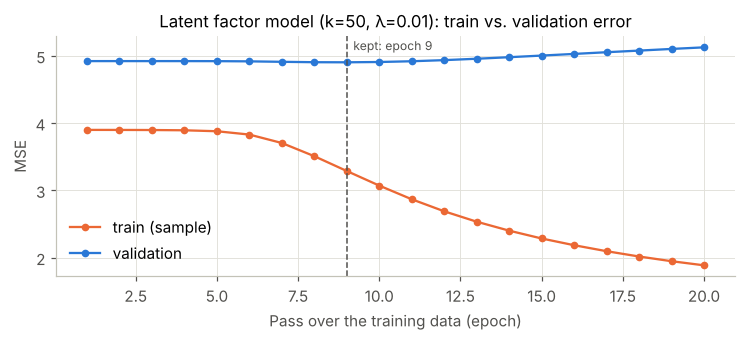

Latent factors (k=50) + full bias model       valid MSE 4.903 | test MSE 5.400


In [ ]:
t0 = time.time()
(best_valid, user_vectors, beer_vectors, best_epoch), latent_history = train_latent_factors(best_k, best_reg, epochs=20, verbose=True)
latent_seconds = time.time() - t0

figure, axis = plt.subplots(figsize=(7, 3.2))
axis.plot(latent_history["epoch"], latent_history["train MSE"], color=second_color, marker="o", markersize=4, label="train (sample)")
axis.plot(latent_history["epoch"], latent_history["valid MSE"], color=main_color, marker="o", markersize=4, label="validation")
axis.axvline(best_epoch, color=text_color, linewidth=1, linestyle="--")
axis.text(best_epoch + 0.2, axis.get_ylim()[1] * 0.995, f"kept: epoch {best_epoch}", va="top", fontsize=8, color=text_color)
axis.set_xlabel("Pass over the training data (epoch)")
axis.set_ylabel("MSE")
axis.set_title(f"Latent factor model (k={best_k}, λ={best_reg}): train vs. validation error")
axis.legend(frameon=False)
plt.tight_layout()
plt.show()

latent_name = f"Latent factors (k={best_k}) + full bias model"
record(latent_name,
       latent_prediction(base_train, u_train, i_train, user_vectors, beer_vectors),
       latent_prediction(base_valid, u_valid, i_valid, user_vectors, beer_vectors),
       latent_prediction(base_test, u_test, i_test, user_vectors, beer_vectors), latent_seconds)

- Tuning: more factors and a smaller λ help, but only slightly. Going from k = 10 to k = 50 lowers validation MSE by just 0.003, so we stopped at 50.
- Overfitting: training error keeps falling with every pass (from 3.90 to 1.89), while validation error bottoms out after 9 passes (4.903) and then rises steadily. Most beers have only a handful of reviews, so their 50 latent numbers are easy to overfit. Keeping the best pass on validation (early stopping) is essential.
- The latent factors improve on the full bias model by only 0.007 in test MSE. The user × style offset already captures most of the taste differences between users, so there is little left for the latent factors to find. In an earlier version without the user × style term, the latent factors helped more (about 0.03), which supports this explanation.

### 3.7 A comparison setting: predicting the score from the review's own text

Section 2.4.5 showed that the words in a review separate low from high scores. As a separate comparison (not a recommender, because the text only exists after the person has tried the beer), we predict the overall score from the text of the same review, using linear regression with an L2 penalty (ridge) on three text representations from class:

1. Bag of words: presence/absence of the 5,000 most common words
2. TF-IDF: the same 5,000 words, weighted by how rare they are across reviews
3. TF-IDF with word pairs: the 20,000 most common words and two-word phrases ("not good", "very sweet")

Trained on 150,000 training reviews, the penalty tuned on 30,000 validation reviews, and scored on 50,000 test reviews. This tells us how much of the score is "written down" in the review, which puts the recommender's error in context.

In [ ]:
text_representations = {
    "Bag of words (5,000 words)": CountVectorizer(max_features=5000, binary=True),
    "TF-IDF (5,000 words)": TfidfVectorizer(max_features=5000, sublinear_tf=True),
    "TF-IDF (20,000 words + word pairs)": TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=5, sublinear_tf=True),
}
text_rows = []
for name, vectorizer in text_representations.items():
    t0 = time.time()
    X_text = {part: vectorizer.fit_transform(text_sample[part]["text"]) if part == "train"
              else vectorizer.transform(text_sample[part]["text"]) for part in ["train", "valid", "test"]}
    y_text = {part: text_sample[part]["overall"].to_numpy(float) for part in ["train", "valid", "test"]}
    best = None
    for alpha in [0.3, 1, 3, 10, 30]:
        ridge = Ridge(alpha=alpha).fit(X_text["train"], y_text["train"])
        valid_mse = mse(y_text["valid"], ridge.predict(X_text["valid"]))
        if best is None or valid_mse < best[0]:
            best = (valid_mse, alpha, ridge)
    test_mse = mse(y_text["test"], np.clip(best[2].predict(X_text["test"]), 1, 20))
    text_rows.append({"representation": name, "chosen α": best[1], "valid MSE": round(best[0], 3),
                      "test MSE": round(test_mse, 3), "time (s)": round(time.time() - t0)})
    print(text_rows[-1])
    if name.startswith("TF-IDF (5,000"):
        tfidf_vocabulary, tfidf_coefficients = vectorizer.get_feature_names_out(), best[2].coef_
text_table = pd.DataFrame(text_rows)
print("Global-mean MSE on the same test reviews:", round(mse(y_text["test"], np.full(len(y_text["test"]), mu)), 3))
display(text_table)

words = pd.Series(tfidf_coefficients, index=tfidf_vocabulary).sort_values()
display(pd.DataFrame({"pulls the score down": words.index[:12], "weight (down)": words.values[:12].round(1),
                      "pulls the score up": words.index[::-1][:12], "weight (up)": words.values[::-1][:12].round(1)}))

{'representation': 'Bag of words (5,000 words)', 'chosen α': 30, 'valid MSE': 5.138, 'test MSE': 5.087, 'time (s)': 15}


{'representation': 'TF-IDF (5,000 words)', 'chosen α': 3, 'valid MSE': 4.624, 'test MSE': 4.682, 'time (s)': 8}


{'representation': 'TF-IDF (20,000 words + word pairs)', 'chosen α': 3, 'valid MSE': 4.346, 'test MSE': 4.438, 'time (s)': 23}
Global-mean MSE on the same test reviews: 9.011


,representation,chosen α,valid MSE,test MSE,time (s)
0,"Bag of words (5,000 words)",30,5.138,5.087,15
1,"TF-IDF (5,000 words)",3,4.624,4.682,8
2,"TF-IDF (20,000 words + word pairs)",3,4.346,4.438,23


,pulls the score down,weight (down),pulls the score up,weight (up)
0,worst,-11.8,perfect,6.3
1,drain,-11.0,excellent,6.0
2,disgusting,-10.3,great,5.8
3,awful,-9.4,delicious,5.7
4,horrible,-8.8,holy,5.7
5,water,-8.8,amazing,5.6
6,nasty,-8.1,fantastic,5.4
7,worse,-7.9,incredible,5.3
8,crap,-7.9,awesome,5.2
9,foul,-7.3,wonderful,5.2


- TF-IDF beats plain bag of words (test MSE 4.68 vs. 5.09). Down-weighting words that appear in nearly every review ("beer", "head", "taste") lets the rarer, opinionated words carry more weight.
- Adding word pairs helps further (4.44). Phrases such as "not bad" or "too sweet" carry sentiment that single words miss.
- The strongest words are what you would expect: "drain" (as in "drain pour"), "disgusting", "water" and "college" pull the score down, and "perfect", "excellent", "delicious" and "heaven" push it up.
- Context for the recommender: the review's own text predicts the score better (4.44) than any model that only knows the past (5.40). That is the gap between predicting someone's opinion and reading it. It is also why review-aware recommenders (Section 5) use other people's reviews of a beer to describe it.

# 4. Evaluation

### 4.1 Why MSE (and FVU)

- MSE is the standard measure for rating prediction and in the related work (Section 5), so our numbers can be compared with theirs. Because errors are squared, it punishes a 6-point miss (predicting 16 for a beer the user hated) much more than several 1-point misses, which matches what a bad recommendation costs.
- Mean absolute error would treat all misses linearly, and ranking metrics (e.g. precision@k) suit a different task: choosing which beers to show rather than predicting a score. We report MSE as the main number.
- FVU (fraction of variance unexplained) = MSE ÷ variance of the test scores rescales MSE so that 1 means "no better than predicting the average" and 0 means perfect. It makes the size of each improvement easy to read.

### 4.2 All models on the test set

Variance of the test scores: 9.008


,train MSE,valid MSE,test MSE,fit time (s),test FVU,vs. global mean
model,,,,,,
Global mean,11.532,9.360,9.088,0.0,1.009,0.0%
Beer average,5.483,5.806,6.096,0.1,0.677,32.9%
User average,9.778,8.344,8.402,0.1,0.933,7.6%
Bias model (user + beer),4.409,5.322,5.864,0.5,0.651,35.5%
"Bias + beer metadata (style, brewer, ABV)",4.394,5.050,5.494,1.1,0.610,39.5%
"Bias + metadata + time (experience, year)",4.370,5.010,5.479,1.7,0.608,39.7%
Bias + metadata + time + user × style,3.874,4.920,5.407,2.3,0.600,40.5%
Latent factors (k=50) + full bias model,3.262,4.903,5.400,83.6,0.599,40.6%


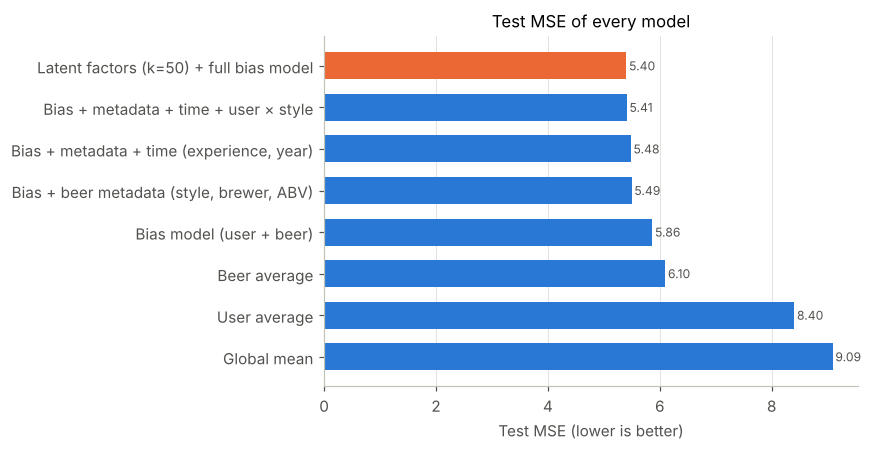

In [ ]:
test_variance = float(np.var(y_test))
results_table = pd.DataFrame(results).set_index("model")
results_table["test FVU"] = results_table["test MSE"] / test_variance
results_table["vs. global mean"] = (1 - results_table["test MSE"] / results_table.loc["Global mean", "test MSE"]).map("{:.1%}".format)
print(f"Variance of the test scores: {test_variance:.3f}")
display(results_table.round(3))

order = results_table["test MSE"].sort_values(ascending=False)
figure, axis = plt.subplots(figsize=(8, 4.2))
colors = [second_color if name == order.index[-1] else main_color for name in order.index]
axis.barh(order.index, order.values, color=colors, height=0.65)
for row_number, value in enumerate(order.values):
    axis.text(value + 0.05, row_number, f"{value:.2f}", va="center", fontsize=8, color=text_color)
axis.set_xlabel("Test MSE (lower is better)")
axis.set_title("Test MSE of every model")
axis.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

- Baselines: predicting the global mean gives test MSE 9.09 (FVU 1.01, slightly above 1 because training scores average lower than test scores). The beer's average alone already removes a third of the error (6.10). The user's average helps much less (8.40), because beers differ more than users do (Section 2.4.6).
- Bias model: one offset per user and per beer gives 5.86 (FVU 0.65).
- Adding style, brewer and ABV offsets is the largest step after that (5.49). Experience and year add a little more (5.48), and the user × style offset brings it to 5.41.
- The latent factor model on top of the full bias model is best: test MSE 5.40, FVU 0.599, 41% lower than predicting the average.
- Test MSEs are higher than validation MSEs for every model, because the test period has more new users and beers (Section 3.2). The order of the models is the same on validation and test.

### 4.3 Is the improvement real?

Bootstrap confidence intervals. We resample the test reviews with replacement 500 times and recompute the difference in MSE between pairs of models on the same resampled reviews. If the 95% interval excludes 0, the difference is not a fluke of which reviews ended up in the test set.

In [ ]:
def bootstrap_difference(name_a, name_b, resamples=500):
    squared_a = (y_test - test_predictions[name_a]) ** 2
    squared_b = (y_test - test_predictions[name_b]) ** 2
    difference = squared_a - squared_b
    boot_rng = np.random.default_rng(SEED)
    means = np.array([difference[boot_rng.integers(0, len(difference), len(difference))].mean() for _ in range(resamples)])
    return difference.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)

comparisons = [
    ("Bias model (user + beer)", "Beer average"),
    ("Bias + beer metadata (style, brewer, ABV)", "Bias model (user + beer)"),
    ("Bias + metadata + time (experience, year)", "Bias + beer metadata (style, brewer, ABV)"),
    ("Bias + metadata + time + user × style", "Bias + metadata + time (experience, year)"),
    (latent_name, "Bias + metadata + time + user × style"),
]
rows = []
for better, worse in comparisons:
    mean_difference, low, high = bootstrap_difference(better, worse)
    rows.append({"model": better, "compared with": worse, "MSE change": round(mean_difference, 4),
                 "95% interval": f"[{low:.4f}, {high:.4f}]", "significant": "yes" if high < 0 or low > 0 else "no"})
display(pd.DataFrame(rows))

,model,compared with,MSE change,95% interval,significant
0,Bias model (user + beer),Beer average,-0.2322,"[-0.2493, -0.2164]",yes
1,"Bias + beer metadata (style, brewer, ABV)",Bias model (user + beer),-0.3691,"[-0.3777, -0.3613]",yes
2,"Bias + metadata + time (experience, year)","Bias + beer metadata (style, brewer, ABV)",-0.0154,"[-0.0203, -0.0102]",yes
3,Bias + metadata + time + user × style,"Bias + metadata + time (experience, year)",-0.0719,"[-0.0784, -0.0641]",yes
4,Latent factors (k=50) + full bias model,Bias + metadata + time + user × style,-0.0072,"[-0.0093, -0.0047]",yes


Latent factor model, test MSE with seeds 1-3: [5.3991 5.4    5.4002] | spread (max - min): 0.0011


- Every step is significant: all five 95% intervals exclude zero. Even the smallest gain, the latent factors on top of the full bias model (−0.007), has an interval of [−0.009, −0.005].
- The order of the models is identical on validation and test, so our choices were not tuned to one particular set of reviews.

### 4.4 Where the models fail: new and rarely seen users and beers

Section 2.4.1 showed that heavy users and popular beers dominate the overall MSE. Here we split the test reviews by how many training reviews the user (and the beer) had.

In [ ]:
def history_group(counts):
    return np.select([counts == 0, counts < 10], ["0 (new)", "1-9"], "10+")

user_group = history_group(train_user_count[u_test])
beer_group = history_group(train_beer_count[i_test])
models_to_show = ["Global mean", "Beer average", "Bias model (user + beer)", "Bias + beer metadata (style, brewer, ABV)",
                  "Bias + metadata + time (experience, year)", "Bias + metadata + time + user × style", latent_name]
breakdown = []
for label, groups in [("user", user_group), ("beer", beer_group)]:
    for group in ["0 (new)", "1-9", "10+"]:
        mask = groups == group
        row = {"split by": label, "training reviews": group, "share of test": f"{mask.mean():.1%}"}
        for name in models_to_show:
            row[name] = mse(y_test[mask], test_predictions[name][mask])
        breakdown.append(row)
breakdown_table = pd.DataFrame(breakdown).set_index(["split by", "training reviews"])
display(breakdown_table.round(2))

share of test  Global mean  Beer average  Bias model (user + beer)  Bias + beer metadata (style, brewer, ABV)  Bias + metadata + time (experience, year)  \
split by training reviews                                                                                                                                                            
user     0 (new)                  23.3%        12.85          7.90                      7.90                                       7.67                                       7.54   
         1-9                       2.5%        10.35          5.94                      7.26                                       7.04                                       7.28   
         10+                      74.3%         7.87          5.54                      5.18                                       4.76                                       4.77   
beer     0 (new)                  30.4%         7.49          7.49                      7.36                                       6.17                                       6.23   
         1-9                      10.0%         8.47          6.33                      5.57                                       5.48                                       5.45   
         10+                      59.6%        10.00          5.35                      5.15                                       5.15                                       5.10   

                           Bias + metadata + time + user × style  Latent factors (k=50) + full bias model  
split by training reviews                                                                                  
user     0 (new)                                            7.55                                     7.55  
         1-9                                                7.21                                     7.21  
         10+                                                4.68                                     4.67  
beer     0 (new)                                            6.13                                     6.13  
         1-9                                                5.38                                     5.38  
         10+                                                5.04                                     5.03

- New users are the hardest case. 23% of test reviews come from users with no training history, and the bias and latent factor models' error on them (7.5–7.9) is far above their error on users with 10+ training reviews (4.7–5.2). With no history, a model can only use what it knows about the beer, and the user-related terms (user offset, user × style, latent factors) contribute nothing.
- New beers are where beer information pays off. For the 30% of test reviews of beers unseen in training, adding style, brewer and ABV offsets cuts the error from 7.36 to 6.17 (6.13 for the final model).
- Frequent users benefit most from the user-specific terms: their error falls from 5.18 (bias model) to 4.67 (final model).
- Possible fixes for new users are discussed in Section 6.

### 4.5 What the fitted parameters tell us

Bias terms. The offsets of the full bias model can be read directly: each is the number of points (out of 20) that a style, an experience level, a year or a (user, style) pair adds to or removes from a prediction, after accounting for everything else.

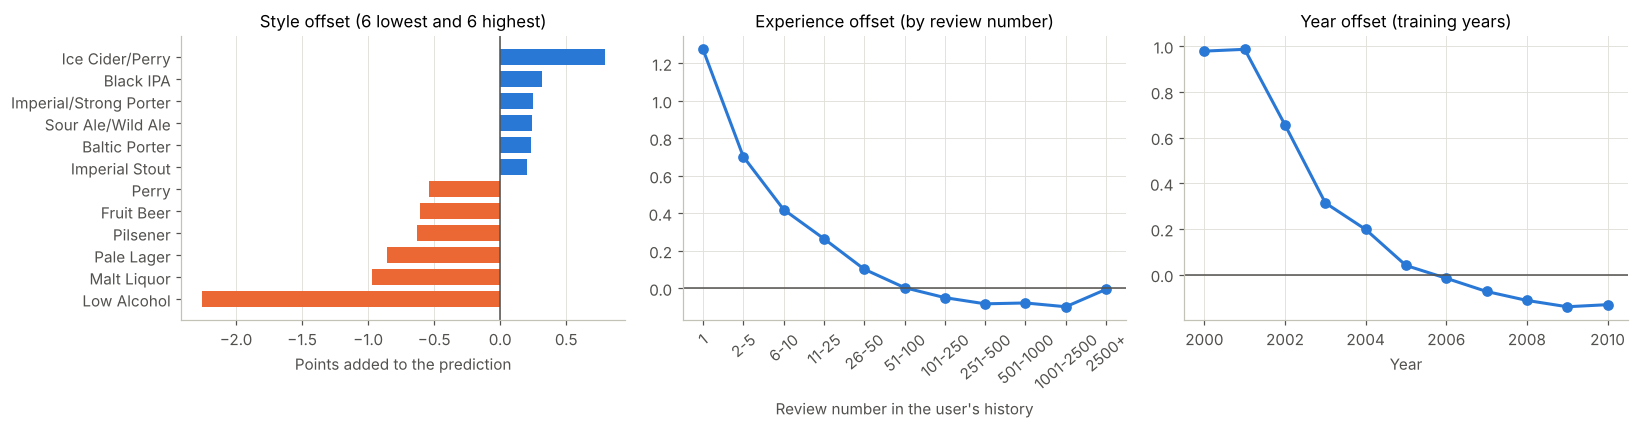

Experience offsets: {'1': 1.27, '2-5': 0.7, '6-10': 0.42, '11-25': 0.26, '26-50': 0.1, '51-100': 0.0, '101-250': -0.05, '251-500': -0.08, '501-1000': -0.08, '1001-2500': -0.1, '2500+': -0.01}
Year offsets: {2000: 0.98, 2001: 0.99, 2002: 0.66, 2003: 0.31, 2004: 0.2, 2005: 0.04, 2006: -0.02, 2007: -0.07, 2008: -0.11, 2009: -0.14, 2010: -0.13}
Style offsets, lowest: {'Low Alcohol': -2.26, 'Malt Liquor': -0.97, 'Pale Lager': -0.86}
Style offsets, highest: {'Imperial/Strong Porter': 0.25, 'Black IPA': 0.32, 'Ice Cider/Perry': 0.79}
User × style offsets for the 26,392 (user, style) pairs with 20+ training reviews: standard deviation 0.52 points, 5% are larger than ±1 point
Beers the model likes most beyond their style and brewer (100+ training reviews):


,beer,style,training reviews,beer offset
i,,,,
71981,Westvleteren 12,Abt/Quadrupel,1793,4.85
49070,De Dolle Stille Nacht Reserva 2000,Belgian Strong Ale,176,4.71
88735,Bells Bourbon Barrel Double Cream/Expedition Stout,Imperial Stout,170,4.58
79085,Three Floyds Oak Aged Dark Lord Russian Imperial Stout,Imperial Stout,235,4.57
55484,AleSmith Barrel Aged Speedway Stout,Imperial Stout,431,4.45
70112,3 Fonteinen J & J Oude Geuze Blauw,Lambic - Gueuze,201,4.38
67158,Russian River Pliny the Younger,Imperial/Double IPA,479,4.31
53410,Kuhnhenn Raspberry Eisbock,Fruit Beer,645,4.28


In [ ]:
style_names = model_df.drop_duplicates("s").set_index("s")["beer_style"].sort_index()
train_style_count = np.bincount(train["s"], minlength=n_levels["s"])
style_offsets = pd.Series(full_bias_offsets["s"], index=style_names.index).rename(style_names)
style_offsets = style_offsets[train_style_count >= 1000].sort_values()
experience_labels = ["1", "2-5", "6-10", "11-25", "26-50", "51-100", "101-250", "251-500", "501-1000", "1001-2500", "2500+"]
first_year = int(model_df["date"].dt.year.min())

figure, axes = plt.subplots(1, 3, figsize=(15, 4))
shown = pd.concat([style_offsets.head(6), style_offsets.tail(6)])
axes[0].barh(shown.index, shown.values, color=[second_color if v < 0 else main_color for v in shown.values], height=0.7)
axes[0].axvline(0, color=text_color, linewidth=1)
axes[0].set_title("Style offset (6 lowest and 6 highest)")
axes[0].set_xlabel("Points added to the prediction")
axes[0].grid(axis="y", visible=False)
axes[1].plot(experience_labels, full_bias_offsets["exp"], color=main_color, marker="o", linewidth=2)
axes[1].axhline(0, color=text_color, linewidth=1)
axes[1].set_xticks(range(len(experience_labels)))
axes[1].set_xticklabels(experience_labels, rotation=40)
axes[1].set_title("Experience offset (by review number)")
axes[1].set_xlabel("Review number in the user's history")
years = np.arange(first_year, last_train_year + 1)
axes[2].plot(years, full_bias_offsets["year"][: len(years)], color=main_color, marker="o", linewidth=2)
axes[2].axhline(0, color=text_color, linewidth=1)
axes[2].set_title("Year offset (training years)")
axes[2].set_xlabel("Year")
plt.tight_layout()
plt.show()

print("Experience offsets:", {label: round(float(v), 2) for label, v in zip(experience_labels, full_bias_offsets["exp"])})
print("Year offsets:", {int(y): round(float(v), 2) for y, v in zip(years, full_bias_offsets["year"])})
print("Style offsets, lowest:", style_offsets.head(3).round(2).to_dict())
print("Style offsets, highest:", style_offsets.tail(3).round(2).to_dict())

beer_ids = model_df.drop_duplicates("i").set_index("i")["beer_id"].sort_index()
beer_table = pd.DataFrame({"beer": beer_name_of.reindex(beer_ids.values).values,
                           "style": beer_style_of.reindex(beer_ids.values).values,
                           "training reviews": train_beer_count,
                           "beer offset": full_bias_offsets["i"]}, index=beer_ids.index)
pair_count = np.bincount(train["us"], minlength=n_levels["us"])
pair_offsets = full_bias_offsets["us"][pair_count >= 20]
print(f"User × style offsets for the {len(pair_offsets):,} (user, style) pairs with 20+ training reviews: "
      f"standard deviation {pair_offsets.std():.2f} points, {np.mean(np.abs(pair_offsets) > 1):.0%} are larger than ±1 point")
print("Beers the model likes most beyond their style and brewer (100+ training reviews):")
display(beer_table[beer_table["training reviews"] >= 100].sort_values("beer offset", ascending=False).head(8).round(2))

- Experience: a user's first review is predicted 1.27 points higher than an otherwise identical review, falling to about 0 by the 50th–100th review and slightly negative afterwards. New reviewers are generous and become stricter, as in Section 2.4.7, but now measured after accounting for which beers they review.
- Year: offsets fall from about +1.0 in 2000–2001 to −0.13 in 2010. The raw average went up over the same years (Section 2.4.2), so the rise in raw scores is explained by which beers were reviewed (more highly rated styles such as imperial stouts) and who was reviewing, not by everyone rating more generously.
- Style: low-alcohol beer (−2.3), malt liquor (−1.0) and pale lager (−0.9) get the lowest offsets. Because each beer also has its own offset, the style offsets matter most for new beers.
- User × style: for (user, style) pairs with 20+ training reviews, the offsets have a standard deviation of about half a point, and 5% are larger than ±1 point. Most users rate styles about as their overall offset suggests, but a minority have strong style preferences.
- Beers: the largest beer offsets go to famous, hard-to-get beers (Westvleteren 12, barrel-aged imperial stouts, 3 Fonteinen geuzes, Pliny the Younger). These score well above even their already high-scoring styles and brewers.

Latent factors. The taste vectors have no labels, but we can look for the main direction along which popular beers differ: we take the beer vectors of beers with at least 200 training reviews, find their first principal direction, and list the styles at each end.

In [ ]:
popular = np.where(train_beer_count >= 200)[0]
vectors = beer_vectors[popular] - beer_vectors[popular].mean(axis=0)
_, singular_values, directions = np.linalg.svd(vectors, full_matrices=False)
score = vectors @ directions[0]
direction_table = pd.DataFrame({"style": beer_table.loc[popular, "style"].values, "score": score})
share_explained = singular_values[0] ** 2 / np.sum(singular_values ** 2)
print(f"{len(popular):,} beers with 200+ training reviews; the first direction explains {share_explained:.0%} of the variation in their vectors")
low_end = direction_table.nsmallest(150, "score")["style"].value_counts().head(6)
high_end = direction_table.nlargest(150, "score")["style"].value_counts().head(6)
display(pd.DataFrame({"one end: style": low_end.index, "beers (of 150)": low_end.values,
                      "other end: style": high_end.index, "beers (of 150) ": high_end.values}))

2,251 beers with 200+ training reviews; the first direction explains 11% of the variation in their vectors


,one end: style,beers (of 150),other end: style,beers (of 150)
0,Porter,11,Pale Lager,15
1,Barley Wine,8,Fruit Beer,13
2,India Pale Ale (IPA),8,Porter,8
3,Belgian Strong Ale,8,Premium Lager,8
4,American Pale Ale,7,American Dark Lager,7
5,Fruit Beer,6,Wheat Ale,7


The main direction explains only 11% of the variation, and the styles at the two ends are mixed (porters and fruit beers appear at both ends). This fits the small gain from the latent factors: the user × style offset already captures preferences between styles, so the factors are left with weaker, harder-to-name patterns. In the earlier version without the user × style term, the main direction clearly separated pale lagers from imperial stouts and barley wines, matching McAuley and Leskovec (2013b), who found that beer rating dimensions line up with beer style.

### 4.6 Practical issues: scale, overfitting, missing data

- Scale: loading 2.9 million reviews from the 400 MB compressed file takes about 35 seconds. We store each repeated value (IDs, styles, scores) once, which keeps memory to a few GB, and drop the review text before modeling. The bias models are fitted with closed-form alternating updates using np.bincount, so a full fit takes 1–2 seconds even with 2.6 million (user, style) offsets. The latent factor model uses vectorised mini-batch SGD (4,096 reviews per step); a pass over the data takes a few seconds, and the 9-setting grid search about 4 minutes. A per-review Python loop would have been far too slow at this size.
- Overfitting: the user-specific terms overfit easily, because many users and (user, style) pairs have only a few reviews. The final model's training MSE (3.26) is far below its validation MSE (4.90). We handled this with L2 regularisation tuned on the time-based validation set, a stronger penalty for the user × style offsets, and early stopping for the latent factors.
- Missing data: ABV is missing for 4.7% of reviews. The bias model gives "ABV missing" its own bin, so no rows were dropped. The 5,185 empty review texts are excluded only from the text comparison.
- Noise: RateBeer scores are integers and people are inconsistent. The best text model, which reads the review itself, still has MSE 4.4, which suggests a good part of the remaining error is noise no model can remove.

# 5. Related work

### 5.1 Where this dataset comes from and how it has been used

- McAuley, Leskovec and Jurafsky (2012) introduced the RateBeer and BeerAdvocate multi-aspect review corpora (together with Amazon and Audible data, about five million reviews rated on three to six aspects). Their model learns which sentences of a review talk about which aspect (appearance, aroma, palate, taste) and with what sentiment. Our text comparison (Section 3.7) is a much simpler version of the same idea: reading the score from the words.
- McAuley and Leskovec (2013a), "From amateurs to connoisseurs", used RateBeer (and BeerAdvocate, CellarTracker, Amazon) to model how tastes change with experience. Each user moves through a series of experience levels, and each level has its own latent factor recommender. On RateBeer overall ratings, their full model lowered MSE from 0.496 to 0.406 compared with a plain latent factor model when predicting users' most recent reviews (about 18%). They rescaled ratings to (0, 5], and their test protocol and models differ from ours, so their absolute MSEs cannot be compared with ours. The course textbook discusses this model in Section 7.3.3.
- McAuley and Leskovec (2013b), "Hidden factors and hidden topics", combined a latent factor rating model with a topic model of the review text, using beer data from RateBeer and BeerAdvocate among others. They found that beer rating dimensions correspond to topics such as beer style, and that review text helps most for users and items with few ratings.

### 5.2 State-of-the-art approaches to rating prediction

- Latent factor models with biases (Koren, Bell and Volinsky, 2009), popularised by the Netflix Prize, are the standard rating-prediction model and are what we implement in Sections 3.5–3.6 (textbook Section 5.1). A key lesson from that work is that the bias terms capture much of the signal and must be modelled carefully.
- Temporal dynamics (Koren, 2009): the timeSVD++ model lets user and item biases drift over time (textbook Section 7.2). Our experience and year offsets are a simple version of this idea.
- Factorization machines (Rendle, 2010) generalise latent factors to arbitrary features such as style or brewer (textbook Section 6.1). Our extended bias model, with style, brewer, ABV and user × style offsets, is a simple special case of this idea without the factorized interactions.

### 5.3 How our results compare

- Bias terms do most of the work, as in Koren et al.: user and beer offsets alone remove 35% of the variance, and everything after that adds a few percent.
- Experience matters, but our gain is smaller. We confirm that first reviews are more generous (+1.3 points), but our shared experience offset improves validation MSE by only about 0.5%, far less than McAuley and Leskovec's 18%. Their model gives each user their own experience progression and changes the whole latent factor model (not just a bias) at each level. This is a clear direction for improvement.
- Style is a main dimension of taste, as in "Hidden factors and hidden topics". Without a user × style term our latent factors rediscovered the lager vs. imperial stout divide, and once we add the user × style term directly, the latent factors have little left to add.
- Text is highly informative, consistent with the multi-aspect work: a ridge regression on TF-IDF features of the review itself beats every recommender. This supports using other users' review text to describe beers, especially new beers with few ratings.

### References

1. Y. Koren. Collaborative filtering with temporal dynamics. KDD 2009.
2. Y. Koren, R. Bell, C. Volinsky. Matrix factorization techniques for recommender systems. IEEE Computer, 2009.
3. J. McAuley. Personalized Machine Learning (course textbook).
4. J. McAuley, J. Leskovec, D. Jurafsky. Learning attitudes and attributes from multi-aspect reviews. ICDM 2012.
5. J. McAuley, J. Leskovec. From amateurs to connoisseurs: modeling the evolution of user expertise through online reviews. WWW 2013. (2013a)
6. J. McAuley, J. Leskovec. Hidden factors and hidden topics: understanding rating dimensions with review text. RecSys 2013. (2013b)
7. S. Rendle. Factorization machines. ICDM 2010.

# 6. Conclusions

What worked
- Simple bias models do most of the work: one offset per user and beer removes 35% of the variance.
- Adding style and brewer offsets is the most useful single extension (39.5%), mainly because it gives sensible predictions for new and rarely reviewed beers.
- A user × style offset adds a clear, significant gain (40.5%). How a person feels about a style matters beyond how generous they are in general.
- The final model, latent factors on top of the full bias model, reaches test MSE 5.40 (FVU 0.599), 41% better than predicting the average. Every improvement is statistically significant.

What didn't help much
- Latent factors add only 0.007 once the user × style offset is in the model, and they overfit after about 9 passes over the data.
- ABV adds almost nothing once style is known, and the year adds little in a forward-in-time split because future years can't be learned from the past.

What the fitted parameters say
- New reviewers are generous (+1.3 points on a first review), and they become stricter over about 50 reviews.
- The long-run rise in average scores is explained by which beers and users were reviewed, not by rising generosity: the year offsets fall once users, beers and styles are accounted for.
- The beers with the biggest positive offsets are rare, famous ones (Westvleteren 12, barrel-aged imperial stouts, 3 Fonteinen geuzes).

Limitations and next steps
- New users (23% of test reviews) remain the weakest case. Ideas: ask new users to rate a few styles when they join (textbook Section 6.2.2), or use other people's review text to describe beers (as in Hidden Factors and Hidden Topics).
- A per-user experience model like McAuley and Leskovec's, instead of our shared offset, could capture the experience effect much better.
- The review's own text predicts the score better (MSE 4.44) than any recommender. Text from other users' reviews of the same beer is an obvious feature to add.